# 边界和数据下载

In [2]:
import rioxarray as rxr
import geopandas as gpd
from shapely.geometry import box

# 读取 TIF 文件
raster = rxr.open_rasterio(r"D:\Onedrive\work\2025-04-20-water\data\ori_index\NDVI\2014.tif")

# 获取栅格的边界（左下和右上坐标）
left, bottom, right, top = raster.rio.bounds()

# 创建一个矩形几何对象
polygon = box(left, bottom, right, top)

# 创建 GeoDataFrame
gdf = gpd.GeoDataFrame(geometry=[polygon], crs=raster.rio.crs)

# 导出为 shapefile
output_path = "data/shp/boundary.shp"
gdf.to_file(output_path)

print(f"边界已导出为 {output_path}")

边界已导出为 data/shp/boundary.shp


In [1]:
import os
import ee
import geemap
os.environ['HTTP_PROXY'] = 'http://127.0.0.1:7890'
os.environ['HTTPS_PROXY'] = 'http://127.0.0.1:7890'
Map = geemap.Map()
geemap.ee_initialize()

In [14]:
# 导入必要的库
import os
import ee
import geemap

# 定义输出路径
output_dir = 'data/lc'
os.makedirs(output_dir, exist_ok=True)

# 加载MCD12产品
mcd12 = ee.ImageCollection("MODIS/061/MCD12Q1")

# 获取边界
gosif_boundary = geemap.shp_to_ee('data/shp/boundary.shp')

# 循环下载2001到2021年的数据
for year in range(2001, 2022):
    # 设置日期范围
    start_date = f'{year}-01-01'
    end_date = f'{year+1}-01-01'
    
    # 过滤指定年份的数据
    mcd12_year = mcd12.filter(ee.Filter.date(start_date, end_date)).first()
    
    # 选择LC_Type1波段(IGBP分类)
    mcd12_lc_type1 = mcd12_year.select('LC_Type1')
    mcd12_clipped = mcd12_lc_type1.clip(gosif_boundary)
    
    # 下载裁剪后的影像
    output_file = os.path.join(output_dir, f'MCD12_{year}.tif')
    geemap.ee_export_image(
        mcd12_clipped, 
        crs='epsg:4326', 
        scale=500, 
        region=gosif_boundary.geometry(), 
        filename=output_file
    )
    
    print(f"MCD12 {year}年土地覆盖数据已下载到: {output_file}")


Generating URL ...
Please wait ...
Data downloaded to d:\Onedrive\work\2025-04-20-water\data\lc\MCD12_2001.tif
MCD12 2001年土地覆盖数据已下载到: data/lc\MCD12_2001.tif
Generating URL ...
Please wait ...
Data downloaded to d:\Onedrive\work\2025-04-20-water\data\lc\MCD12_2002.tif
MCD12 2002年土地覆盖数据已下载到: data/lc\MCD12_2002.tif
Generating URL ...
Please wait ...
Data downloaded to d:\Onedrive\work\2025-04-20-water\data\lc\MCD12_2003.tif
MCD12 2003年土地覆盖数据已下载到: data/lc\MCD12_2003.tif
Generating URL ...
Please wait ...
Data downloaded to d:\Onedrive\work\2025-04-20-water\data\lc\MCD12_2004.tif
MCD12 2004年土地覆盖数据已下载到: data/lc\MCD12_2004.tif
Generating URL ...
Please wait ...
Data downloaded to d:\Onedrive\work\2025-04-20-water\data\lc\MCD12_2005.tif
MCD12 2005年土地覆盖数据已下载到: data/lc\MCD12_2005.tif
Generating URL ...
Please wait ...
Data downloaded to d:\Onedrive\work\2025-04-20-water\data\lc\MCD12_2006.tif
MCD12 2006年土地覆盖数据已下载到: data/lc\MCD12_2006.tif
Generating URL ...
Please wait ...
Data downloaded to d:\O

In [21]:
# 循环下载2001到2021年的数据
for year in range(2001, 2022):
    # 设置日期范围
    start_date = f'{year}-01-01'
    end_date = f'{year+1}-01-01'
    
    # 过滤指定年份的数据
    dataset = ee.ImageCollection('WorldPop/GP/100m/pop')
    raster = dataset.select('population').filterDate(start_date, end_date).mean()
    
    # 下载裁剪后的影像
    output_file = os.path.join(output_dir, f'pop_{year}.tif')
    geemap.ee_export_image(
        raster, 
        crs='epsg:4326', 
        scale=500, 
        region=gosif_boundary.geometry(), 
        filename=output_file
    )
    
    print(f"WorldPop {year}年人口数据已下载到: {output_file}")

Generating URL ...
Please wait ...
Data downloaded to d:\Onedrive\work\2025-04-20-water\data\lc\pop_2001.tif
WorldPop 2001年人口数据已下载到: data/lc\pop_2001.tif
Generating URL ...
Please wait ...
Data downloaded to d:\Onedrive\work\2025-04-20-water\data\lc\pop_2002.tif
WorldPop 2002年人口数据已下载到: data/lc\pop_2002.tif
Generating URL ...
Please wait ...
Data downloaded to d:\Onedrive\work\2025-04-20-water\data\lc\pop_2003.tif
WorldPop 2003年人口数据已下载到: data/lc\pop_2003.tif
Generating URL ...
Please wait ...
Data downloaded to d:\Onedrive\work\2025-04-20-water\data\lc\pop_2004.tif
WorldPop 2004年人口数据已下载到: data/lc\pop_2004.tif
Generating URL ...
Please wait ...
Data downloaded to d:\Onedrive\work\2025-04-20-water\data\lc\pop_2005.tif
WorldPop 2005年人口数据已下载到: data/lc\pop_2005.tif
Generating URL ...
Please wait ...
Data downloaded to d:\Onedrive\work\2025-04-20-water\data\lc\pop_2006.tif
WorldPop 2006年人口数据已下载到: data/lc\pop_2006.tif
Generating URL ...
Please wait ...
Data downloaded to d:\Onedrive\work\2025-

In [5]:
# 循环下载2001到2021年的数据
output_dir = 'data/ndvi'
gosif_boundary = geemap.shp_to_ee('data/shp/boundary.shp')
os.makedirs(output_dir, exist_ok=True)
for year in range(2001, 2022):
    # 设置日期范围
    start_date = f'{year}-01-01'
    end_date = f'{year+1}-01-01'
    
    # 过滤指定年份的数据
    dataset = ee.ImageCollection('MODIS/061/MOD13Q1')
    raster = dataset.filterDate(start_date, end_date).select('NDVI').mean()
    
    # 下载裁剪后的影像
    output_file = os.path.join(output_dir, f'NDVI_{year}.tif')
    geemap.ee_export_image(
        raster, 
        crs='epsg:4326', 
        scale=500,  # MODIS NDVI的分辨率是250米
        region=gosif_boundary.geometry(), 
        filename=output_file
    )
    
    print(f"MODIS NDVI {year}年数据已下载到: {output_file}")

Generating URL ...
Please wait ...
Data downloaded to d:\Onedrive\work\2025-04-20-water\data\ndvi\NDVI_2001.tif
MODIS NDVI 2001年数据已下载到: data/ndvi\NDVI_2001.tif
Generating URL ...
Please wait ...
Data downloaded to d:\Onedrive\work\2025-04-20-water\data\ndvi\NDVI_2002.tif
MODIS NDVI 2002年数据已下载到: data/ndvi\NDVI_2002.tif
Generating URL ...
Please wait ...
Data downloaded to d:\Onedrive\work\2025-04-20-water\data\ndvi\NDVI_2003.tif
MODIS NDVI 2003年数据已下载到: data/ndvi\NDVI_2003.tif
Generating URL ...
Please wait ...
Data downloaded to d:\Onedrive\work\2025-04-20-water\data\ndvi\NDVI_2004.tif
MODIS NDVI 2004年数据已下载到: data/ndvi\NDVI_2004.tif
Generating URL ...
Please wait ...
Data downloaded to d:\Onedrive\work\2025-04-20-water\data\ndvi\NDVI_2005.tif
MODIS NDVI 2005年数据已下载到: data/ndvi\NDVI_2005.tif
Generating URL ...
Please wait ...
Data downloaded to d:\Onedrive\work\2025-04-20-water\data\ndvi\NDVI_2006.tif
MODIS NDVI 2006年数据已下载到: data/ndvi\NDVI_2006.tif
Generating URL ...
Please wait ...
Data 

In [6]:
# 循环下载2001到2013年的夜间灯光数据
output_dir = 'data/night'
gosif_boundary = geemap.shp_to_ee('data/shp/boundary.shp')
os.makedirs(output_dir, exist_ok=True)
for year in range(2001, 2014):
    # 设置日期范围
    start_date = f'{year}-01-01'
    end_date = f'{year+1}-01-01'
    
    # 过滤指定年份的数据
    dataset = ee.ImageCollection('NOAA/DMSP-OLS/NIGHTTIME_LIGHTS')
    raster = dataset.filterDate(start_date, end_date).select('avg_vis').mean()
    
    # 下载裁剪后的影像
    output_file = os.path.join(output_dir, f'night_{year}.tif')
    geemap.ee_export_image(
        raster, 
        crs='epsg:4326', 
        scale=500,
        region=gosif_boundary.geometry(), 
        filename=output_file
    )
    
    print(f"夜间灯光 {year}年数据已下载到: {output_file}")


Generating URL ...
Please wait ...
Data downloaded to d:\Onedrive\work\2025-04-20-water\data\night\night_2001.tif
夜间灯光 2001年数据已下载到: data/night\night_2001.tif
Generating URL ...
Please wait ...
Data downloaded to d:\Onedrive\work\2025-04-20-water\data\night\night_2002.tif
夜间灯光 2002年数据已下载到: data/night\night_2002.tif
Generating URL ...
Please wait ...
Data downloaded to d:\Onedrive\work\2025-04-20-water\data\night\night_2003.tif
夜间灯光 2003年数据已下载到: data/night\night_2003.tif
Generating URL ...
Please wait ...
Data downloaded to d:\Onedrive\work\2025-04-20-water\data\night\night_2004.tif
夜间灯光 2004年数据已下载到: data/night\night_2004.tif
Generating URL ...
Please wait ...
Data downloaded to d:\Onedrive\work\2025-04-20-water\data\night\night_2005.tif
夜间灯光 2005年数据已下载到: data/night\night_2005.tif
Generating URL ...
Please wait ...
Data downloaded to d:\Onedrive\work\2025-04-20-water\data\night\night_2006.tif
夜间灯光 2006年数据已下载到: data/night\night_2006.tif
Generating URL ...
Please wait ...
Data downloaded t

In [7]:
# 循环下载2014到2021年的夜间灯光数据
output_dir = 'data/night'
gosif_boundary = geemap.shp_to_ee('data/shp/boundary.shp')
os.makedirs(output_dir, exist_ok=True)
for year in range(2014, 2022):
    # 设置日期范围
    start_date = f'{year}-01-01'
    end_date = f'{year+1}-01-01'
    
    # 过滤指定年份的数据
    dataset = ee.ImageCollection('NOAA/VIIRS/DNB/MONTHLY_V1/VCMSLCFG')
    raster = dataset.filterDate(start_date, end_date).select('avg_rad').mean()
    
    # 下载裁剪后的影像
    output_file = os.path.join(output_dir, f'night_{year}.tif')
    geemap.ee_export_image(
        raster, 
        crs='epsg:4326', 
        scale=500,
        region=gosif_boundary.geometry(), 
        filename=output_file
    )
    
    print(f"夜间灯光 {year}年数据已下载到: {output_file}")


Generating URL ...
Please wait ...
Data downloaded to d:\Onedrive\work\2025-04-20-water\data\night\night_2014.tif
夜间灯光 2014年数据已下载到: data/night\night_2014.tif
Generating URL ...
Please wait ...
Data downloaded to d:\Onedrive\work\2025-04-20-water\data\night\night_2015.tif
夜间灯光 2015年数据已下载到: data/night\night_2015.tif
Generating URL ...
Please wait ...
Data downloaded to d:\Onedrive\work\2025-04-20-water\data\night\night_2016.tif
夜间灯光 2016年数据已下载到: data/night\night_2016.tif
Generating URL ...
Please wait ...
Data downloaded to d:\Onedrive\work\2025-04-20-water\data\night\night_2017.tif
夜间灯光 2017年数据已下载到: data/night\night_2017.tif
Generating URL ...
Please wait ...
Data downloaded to d:\Onedrive\work\2025-04-20-water\data\night\night_2018.tif
夜间灯光 2018年数据已下载到: data/night\night_2018.tif
Generating URL ...
Please wait ...
Data downloaded to d:\Onedrive\work\2025-04-20-water\data\night\night_2019.tif
夜间灯光 2019年数据已下载到: data/night\night_2019.tif
Generating URL ...
Please wait ...
Data downloaded t

## 处理tif维度

In [8]:
import os
import glob
import rioxarray
import xarray as xr
from pathlib import Path

# 定义路径
input_dir = r"D:\Onedrive\work\2025-04-20-water\data\night"
reference_file = r"D:\Onedrive\work\2025-04-20-water\data\lc\MCD12_2001.tif"
output_dir = r"D:\Onedrive\work\2025-04-20-water\data\night_mask"

# 确保输出目录存在
os.makedirs(output_dir, exist_ok=True)

# 读取参考文件
reference_raster = rioxarray.open_rasterio(reference_file)

# 获取所有TIF文件
tif_files = glob.glob(os.path.join(input_dir, "*.tif"))
print(f"找到{len(tif_files)}个TIF文件需要处理。")

# 遍历并处理每个TIF文件
for tif_file in tif_files:
    file_name = os.path.basename(tif_file)
    output_path = os.path.join(output_dir, file_name)
    
    print(f"处理: {file_name}")
    
    try:
        # 打开源文件
        with rioxarray.open_rasterio(tif_file) as src:
            # 将源文件重投影到参考文件的CRS
            if src.rio.crs != reference_raster.rio.crs:
                src = src.rio.reproject(reference_raster.rio.crs)
            
            # 裁剪到参考文件的范围
            clipped = src.rio.clip_box(
                minx=reference_raster.rio.bounds()[0],
                miny=reference_raster.rio.bounds()[1],
                maxx=reference_raster.rio.bounds()[2],
                maxy=reference_raster.rio.bounds()[3]
            )
            
            # 重采样到参考文件的分辨率和尺寸
            resampled = clipped.rio.reproject_match(reference_raster)
            
            # 保存处理后的文件
            resampled.rio.to_raster(output_path)
            
            print(f"完成: {output_path}")
    except Exception as e:
        print(f"处理文件 {file_name} 时出错: {str(e)}")

print("所有文件处理完成！")

找到21个TIF文件需要处理。
处理: DMSP2001.tif
完成: D:\Onedrive\work\2025-04-20-water\data\night_mask\DMSP2001.tif
处理: DMSP2002.tif
完成: D:\Onedrive\work\2025-04-20-water\data\night_mask\DMSP2002.tif
处理: DMSP2003.tif
完成: D:\Onedrive\work\2025-04-20-water\data\night_mask\DMSP2003.tif
处理: DMSP2004.tif
完成: D:\Onedrive\work\2025-04-20-water\data\night_mask\DMSP2004.tif
处理: DMSP2005.tif
完成: D:\Onedrive\work\2025-04-20-water\data\night_mask\DMSP2005.tif
处理: DMSP2006.tif
完成: D:\Onedrive\work\2025-04-20-water\data\night_mask\DMSP2006.tif
处理: DMSP2007.tif
完成: D:\Onedrive\work\2025-04-20-water\data\night_mask\DMSP2007.tif
处理: DMSP2008.tif
完成: D:\Onedrive\work\2025-04-20-water\data\night_mask\DMSP2008.tif
处理: DMSP2009.tif
完成: D:\Onedrive\work\2025-04-20-water\data\night_mask\DMSP2009.tif
处理: DMSP2010.tif
完成: D:\Onedrive\work\2025-04-20-water\data\night_mask\DMSP2010.tif
处理: DMSP2011.tif
完成: D:\Onedrive\work\2025-04-20-water\data\night_mask\DMSP2011.tif
处理: DMSP2012.tif
完成: D:\Onedrive\work\2025-04-20-water\data\

## 计算SHDI

In [9]:
import numpy as np
import os
import rasterio
from rasterio.windows import Window
from scipy.stats import entropy
import glob
from tqdm import tqdm

# 定义输入和输出目录
input_dir = r"D:\Onedrive\work\2025-04-20-water\data\lc"
output_dir = r"D:\Onedrive\work\2025-04-20-water\data\shdi"

# 确保输出目录存在
os.makedirs(output_dir, exist_ok=True)

# 获取所有TIF文件
tif_files = glob.glob(os.path.join(input_dir, "*.tif"))
print(f"找到{len(tif_files)}个TIF文件需要计算SHDI。")

# 定义计算SHDI的函数
def calculate_shdi(array, window_size=5):
    """
    计算Shannon多样性指数 (SHDI)
    
    参数:
    array: 包含土地覆盖类型的2D数组
    window_size: 滑动窗口大小
    
    返回:
    shdi_array: 与输入相同大小的SHDI数组
    """
    # 创建输出数组，初始化为NaN
    height, width = array.shape
    shdi_array = np.full((height, width), np.nan)
    
    # 窗口的半径
    radius = window_size // 2
    
    # 遍历每个像素
    for i in range(height):
        for j in range(width):
            # 定义窗口边界
            y_min = max(0, i - radius)
            y_max = min(height, i + radius + 1)
            x_min = max(0, j - radius)
            x_max = min(width, j + radius + 1)
            
            # 提取窗口
            window = array[y_min:y_max, x_min:x_max]
            
            # 计算窗口中每个类别的频率
            unique_values = np.unique(window[~np.isnan(window)])
            if len(unique_values) > 0:
                counts = np.array([np.sum(window == val) for val in unique_values])
                proportions = counts / np.sum(counts)
                
                # 计算Shannon指数
                shdi = -np.sum(proportions * np.log(proportions))
                shdi_array[i, j] = shdi
    
    return shdi_array

# 遍历并处理每个TIF文件
for tif_file in tqdm(tif_files, desc="处理文件"):
    file_name = os.path.basename(tif_file)
    output_path = os.path.join(output_dir, file_name.replace('.tif', '_shdi.tif'))
    
    try:
        # 打开源文件
        with rasterio.open(tif_file) as src:
            # 读取数据
            data = src.read(1)
            
            # 计算SHDI
            shdi_data = calculate_shdi(data, window_size=5)
            
            # 创建输出文件的配置
            output_profile = src.profile.copy()
            output_profile.update(
                dtype=rasterio.float32,
                count=1,
                nodata=np.nan
            )
            
            # 保存SHDI结果
            with rasterio.open(output_path, 'w', **output_profile) as dst:
                dst.write(shdi_data.astype(rasterio.float32), 1)
            
            print(f"完成: {output_path}")
    except Exception as e:
        print(f"处理文件 {file_name} 时出错: {str(e)}")

print("所有SHDI计算完成！")


找到21个TIF文件需要计算SHDI。


处理文件:   5%|▍         | 1/21 [00:25<08:33, 25.69s/it]

完成: D:\Onedrive\work\2025-04-20-water\data\shdi\MCD12_2001_shdi.tif


处理文件:  10%|▉         | 2/21 [00:50<07:55, 25.05s/it]

完成: D:\Onedrive\work\2025-04-20-water\data\shdi\MCD12_2002_shdi.tif


...

完成: D:\Onedrive\work\2025-04-20-water\data\shdi\MCD12_2019_shdi.tif


处理文件:  95%|█████████▌| 20/21 [08:02<00:23, 23.89s/it]

完成: D:\Onedrive\work\2025-04-20-water\data\shdi\MCD12_2020_shdi.tif


处理文件: 100%|██████████| 21/21 [08:25<00:00, 24.09s/it]

完成: D:\Onedrive\work\2025-04-20-water\data\shdi\MCD12_2021_shdi.tif
所有SHDI计算完成！


## 计算SHEI

In [69]:
import numpy as np
import os
import rasterio
from rasterio.windows import Window
from scipy.stats import entropy
import glob
from tqdm import tqdm

# 定义输入和输出目录
input_dir = "data/lc"
output_dir = "data/shei"

# 确保输出目录存在
os.makedirs(output_dir, exist_ok=True)

# 获取所有TIF文件
tif_files = glob.glob(os.path.join(input_dir, "*.tif"))
print(f"找到{len(tif_files)}个TIF文件需要计算SHEI。")

# 定义计算SHEI的函数
def calculate_shei(array, window_size=5):
    """
    计算Shannon均匀度指数 (SHEI)
    
    参数:
    array: 包含土地覆盖类型的2D数组
    window_size: 滑动窗口大小
    
    返回:
    shei_array: 与输入相同大小的SHEI数组
    """
    # 创建输出数组，初始化为NaN
    height, width = array.shape
    shei_array = np.full((height, width), np.nan)
    
    # 窗口的半径
    radius = window_size // 2
    
    # 遍历每个像素
    for i in range(height):
        for j in range(width):
            # 定义窗口边界
            y_min = max(0, i - radius)
            y_max = min(height, i + radius + 1)
            x_min = max(0, j - radius)
            x_max = min(width, j + radius + 1)
            
            # 提取窗口
            window = array[y_min:y_max, x_min:x_max]
            
            # 计算窗口中每个类别的频率
            unique_values = np.unique(window[~np.isnan(window)])
            if len(unique_values) > 1:  # 至少需要两个不同的类别
                counts = np.array([np.sum(window == val) for val in unique_values])
                proportions = counts / np.sum(counts)
                
                # 计算Shannon指数
                shdi = -np.sum(proportions * np.log(proportions))
                
                # 计算SHEI = SHDI / ln(S)，其中S是类别数量
                ln_s = np.log(len(unique_values))
                shei = shdi / ln_s
                
                shei_array[i, j] = shei
            elif len(unique_values) == 1:  # 只有一种类别时，均匀度为0
                shei_array[i, j] = 0
    
    return shei_array

# 遍历并处理每个TIF文件
for tif_file in tqdm(tif_files, desc="处理文件"):
    file_name = os.path.basename(tif_file)
    output_path = os.path.join(output_dir, file_name.replace('.tif', '_shei.tif'))
    
    try:
        # 打开源文件
        with rasterio.open(tif_file) as src:
            # 读取数据
            data = src.read(1)
            
            # 计算SHEI
            shei_data = calculate_shei(data, window_size=5)
            
            # 创建输出文件的配置
            output_profile = src.profile.copy()
            output_profile.update(
                dtype=rasterio.float32,
                count=1,
                nodata=np.nan
            )
            
            # 保存SHEI结果
            with rasterio.open(output_path, 'w', **output_profile) as dst:
                dst.write(shei_data.astype(rasterio.float32), 1)
            
            print(f"完成: {output_path}")
    except Exception as e:
        print(f"处理文件 {file_name} 时出错: {str(e)}")

print("所有SHEI计算完成！")

找到21个TIF文件需要计算SHEI。


处理文件:   5%|▍         | 1/21 [00:17<05:59, 17.97s/it]

完成: data/shei\MCD12_2001_shei.tif


处理文件:  10%|▉         | 2/21 [00:32<04:59, 15.75s/it]

完成: data/shei\MCD12_2002_shei.tif


...

完成: data/shei\MCD12_2019_shei.tif


处理文件:  95%|█████████▌| 20/21 [04:35<00:13, 13.74s/it]

完成: data/shei\MCD12_2020_shei.tif


处理文件: 100%|██████████| 21/21 [04:49<00:00, 13.79s/it]

完成: data/shei\MCD12_2021_shei.tif
所有SHEI计算完成！


## 计算DIVISION

In [70]:
import numpy as np
import os
import rasterio
from rasterio.windows import Window
import glob
from tqdm import tqdm

# 定义输入和输出目录
input_dir = "data/lc"
output_dir = "data/division"

# 确保输出目录存在
os.makedirs(output_dir, exist_ok=True)

# 获取所有TIF文件
tif_files = glob.glob(os.path.join(input_dir, "*.tif"))
print(f"找到{len(tif_files)}个TIF文件需要计算DIVISION。")

# 定义计算DIVISION的函数
def calculate_division(array, window_size=5):
    """
    计算景观分割度指数 (DIVISION)
    
    参数:
    array: 包含土地覆盖类型的2D数组
    window_size: 滑动窗口大小
    
    返回:
    division_array: 与输入相同大小的DIVISION数组
    """
    # 创建输出数组，初始化为NaN
    height, width = array.shape
    division_array = np.full((height, width), np.nan)
    
    # 窗口的半径
    radius = window_size // 2
    
    # 遍历每个像素
    for i in range(height):
        for j in range(width):
            # 定义窗口边界
            y_min = max(0, i - radius)
            y_max = min(height, i + radius + 1)
            x_min = max(0, j - radius)
            x_max = min(width, j + radius + 1)
            
            # 提取窗口
            window = array[y_min:y_max, x_min:x_max]
            
            # 计算窗口中每个类别的频率
            unique_values = np.unique(window[~np.isnan(window)])
            if len(unique_values) > 0:
                total_pixels = np.sum(~np.isnan(window))
                
                # 计算每个类别的比例的平方和
                sum_squared_proportions = 0
                for val in unique_values:
                    class_count = np.sum(window == val)
                    proportion = class_count / total_pixels
                    sum_squared_proportions += proportion ** 2
                
                # 计算DIVISION = 1 - 各类型面积占比的平方和
                division = 1 - sum_squared_proportions
                division_array[i, j] = division
    
    return division_array

# 遍历并处理每个TIF文件
for tif_file in tqdm(tif_files, desc="处理文件"):
    file_name = os.path.basename(tif_file)
    output_path = os.path.join(output_dir, file_name.replace('.tif', '_division.tif'))
    
    try:
        # 打开源文件
        with rasterio.open(tif_file) as src:
            # 读取数据
            data = src.read(1)
            
            # 计算DIVISION
            division_data = calculate_division(data, window_size=5)
            
            # 创建输出文件的配置
            output_profile = src.profile.copy()
            output_profile.update(
                dtype=rasterio.float32,
                count=1,
                nodata=np.nan
            )
            
            # 保存DIVISION结果
            with rasterio.open(output_path, 'w', **output_profile) as dst:
                dst.write(division_data.astype(rasterio.float32), 1)
            
            print(f"完成: {output_path}")
    except Exception as e:
        print(f"处理文件 {file_name} 时出错: {str(e)}")

print("所有DIVISION计算完成！")

找到21个TIF文件需要计算DIVISION。


处理文件:   5%|▍         | 1/21 [00:21<07:13, 21.67s/it]

完成: data/division\MCD12_2001_division.tif


处理文件:  10%|▉         | 2/21 [00:41<06:33, 20.70s/it]

完成: data/division\MCD12_2002_division.tif


...

完成: data/division\MCD12_2019_division.tif


处理文件:  95%|█████████▌| 20/21 [07:03<00:21, 21.47s/it]

完成: data/division\MCD12_2020_division.tif


处理文件: 100%|██████████| 21/21 [07:24<00:00, 21.16s/it]

完成: data/division\MCD12_2021_division.tif
所有DIVISION计算完成！


## 计算CONTAG

In [71]:
import numpy as np
import os
import rasterio
import glob
from tqdm import tqdm

# 定义输入和输出目录
input_dir = "data/lc"
output_dir = "data/contag"

# 确保输出目录存在
os.makedirs(output_dir, exist_ok=True)

# 获取所有TIF文件
tif_files = glob.glob(os.path.join(input_dir, "*.tif"))
print(f"找到{len(tif_files)}个TIF文件需要计算CONTAG。")

# 定义计算CONTAG的函数
def calculate_contag(array, window_size=5):
    """
    计算景观蔓延度指数 (CONTAG)
    
    参数:
    array: 包含土地覆盖类型的2D数组
    window_size: 滑动窗口大小
    
    返回:
    contag_array: 与输入相同大小的CONTAG数组
    """
    # 创建输出数组，初始化为NaN
    height, width = array.shape
    contag_array = np.full((height, width), np.nan)
    
    # 窗口的半径
    radius = window_size // 2
    
    # 定义邻域方向 (4方向: 右、下、左、上)
    directions = [(0, 1), (1, 0), (0, -1), (-1, 0)]
    
    # 遍历每个像素
    for i in range(height):
        for j in range(width):
            # 定义窗口边界
            y_min = max(0, i - radius)
            y_max = min(height, i + radius + 1)
            x_min = max(0, j - radius)
            x_max = min(width, j + radius + 1)
            
            # 提取窗口
            window = array[y_min:y_max, x_min:x_max]
            
            # 获取窗口中的有效值
            valid_mask = ~np.isnan(window)
            if not np.any(valid_mask):
                continue
                
            # 计算窗口中每个类别的频率
            unique_values = np.unique(window[valid_mask])
            
            if len(unique_values) > 1:  # 至少需要两个不同的类别
                # 计算每个类型的比例
                total_valid_pixels = np.sum(valid_mask)
                proportions = {}
                for val in unique_values:
                    proportions[val] = np.sum(window == val) / total_valid_pixels
                
                # 计算邻接概率
                total_adjacencies = 0
                adjacency_counts = {}
                
                # 窗口内部遍历（不包括边界）
                for y in range(y_min+1, y_max-1):
                    for x in range(x_min+1, x_max-1):
                        if np.isnan(array[y, x]):
                            continue
                            
                        center_type = array[y, x]
                        
                        # 检查四个方向的邻居
                        for dy, dx in directions:
                            ny, nx = y + dy, x + dx
                            if y_min <= ny < y_max and x_min <= nx < x_max and not np.isnan(array[ny, nx]):
                                neighbor_type = array[ny, nx]
                                pair = (center_type, neighbor_type)
                                
                                if pair not in adjacency_counts:
                                    adjacency_counts[pair] = 0
                                adjacency_counts[pair] += 1
                                total_adjacencies += 1
                
                # 如果没有足够的邻接关系，跳过
                if total_adjacencies == 0:
                    continue
                
                # 计算邻接概率 P(i,j)
                p_ij = {}
                for pair, count in adjacency_counts.items():
                    p_ij[pair] = count / total_adjacencies
                
                # 计算条件概率 P(i|j) = P(i,j) / P(j)
                sum_pij_log_pij_div_pi = 0
                for pair, prob in p_ij.items():
                    i_type, j_type = pair
                    if proportions[i_type] > 0:
                        conditional_prob = prob / proportions[j_type]
                        if conditional_prob > 0:
                            sum_pij_log_pij_div_pi += proportions[j_type] * conditional_prob * np.log(conditional_prob)
                
                # 计算最大可能的熵
                m = len(unique_values)
                if m > 1:
                    max_entropy = 2 * m * np.log(m)
                    
                    # 计算CONTAG
                    contag = 100 * (1 + sum_pij_log_pij_div_pi / max_entropy)
                    contag_array[i, j] = contag
            elif len(unique_values) == 1:  # 只有一种类别时，蔓延度为100%
                contag_array[i, j] = 100
    
    return contag_array

# 遍历并处理每个TIF文件
for tif_file in tqdm(tif_files, desc="处理文件"):
    file_name = os.path.basename(tif_file)
    output_path = os.path.join(output_dir, file_name.replace('.tif', '_contag.tif'))
    
    try:
        # 打开源文件
        with rasterio.open(tif_file) as src:
            # 读取数据
            data = src.read(1)
            
            # 计算CONTAG
            contag_data = calculate_contag(data, window_size=5)
            
            # 创建输出文件的配置
            output_profile = src.profile.copy()
            output_profile.update(
                dtype=rasterio.float32,
                count=1,
                nodata=np.nan
            )
            
            # 保存CONTAG结果
            with rasterio.open(output_path, 'w', **output_profile) as dst:
                dst.write(contag_data.astype(rasterio.float32), 1)
            
            print(f"完成: {output_path}")
    except Exception as e:
        print(f"处理文件 {file_name} 时出错: {str(e)}")

print("所有CONTAG计算完成！")

找到21个TIF文件需要计算CONTAG。


处理文件:   5%|▍         | 1/21 [00:46<15:21, 46.08s/it]

完成: data/contag\MCD12_2001_contag.tif


处理文件:  10%|▉         | 2/21 [01:19<12:14, 38.66s/it]

完成: data/contag\MCD12_2002_contag.tif


...

完成: data/contag\MCD12_2019_contag.tif


处理文件:  95%|█████████▌| 20/21 [10:33<00:31, 31.29s/it]

完成: data/contag\MCD12_2020_contag.tif


处理文件: 100%|██████████| 21/21 [11:04<00:00, 31.66s/it]

完成: data/contag\MCD12_2021_contag.tif
所有CONTAG计算完成！


## 计算COHESION

In [ ]:
import numpy as np
import os
import rasterio
from rasterio.windows import Window
from scipy.stats import entropy
import glob
from tqdm import tqdm

# 定义输入和输出目录
input_dir = r"D:\Onedrive\work\2025-04-20-water\data\lc"
output_dir = r"D:\Onedrive\work\2025-04-20-water\data\shdi"

# 确保输出目录存在
os.makedirs(output_dir, exist_ok=True)

# 获取所有TIF文件
tif_files = glob.glob(os.path.join(input_dir, "*.tif"))
print(f"找到{len(tif_files)}个TIF文件需要计算SHDI。")

# 定义计算SHDI的函数
def calculate_shdi(array, window_size=5):
    """
    计算Shannon多样性指数 (SHDI)
    
    参数:
    array: 包含土地覆盖类型的2D数组
    window_size: 滑动窗口大小
    
    返回:
    shdi_array: 与输入相同大小的SHDI数组
    """
    # 创建输出数组，初始化为NaN
    height, width = array.shape
    shdi_array = np.full((height, width), np.nan)
    
    # 窗口的半径
    radius = window_size // 2
    
    # 遍历每个像素
    for i in range(height):
        for j in range(width):
            # 定义窗口边界
            y_min = max(0, i - radius)
            y_max = min(height, i + radius + 1)
            x_min = max(0, j - radius)
            x_max = min(width, j + radius + 1)
            
            # 提取窗口
            window = array[y_min:y_max, x_min:x_max]
            
            # 计算窗口中每个类别的频率
            unique_values = np.unique(window[~np.isnan(window)])
            if len(unique_values) > 0:
                counts = np.array([np.sum(window == val) for val in unique_values])
                proportions = counts / np.sum(counts)
                
                # 计算Shannon指数
                shdi = -np.sum(proportions * np.log(proportions))
                shdi_array[i, j] = shdi
    
    return shdi_array

# 遍历并处理每个TIF文件
for tif_file in tqdm(tif_files, desc="处理文件"):
    file_name = os.path.basename(tif_file)
    output_path = os.path.join(output_dir, file_name.replace('.tif', '_shdi.tif'))
    
    try:
        # 打开源文件
        with rasterio.open(tif_file) as src:
            # 读取数据
            data = src.read(1)
            
            # 计算SHDI
            shdi_data = calculate_shdi(data, window_size=5)
            
            # 创建输出文件的配置
            output_profile = src.profile.copy()
            output_profile.update(
                dtype=rasterio.float32,
                count=1,
                nodata=np.nan
            )
            
            # 保存SHDI结果
            with rasterio.open(output_path, 'w', **output_profile) as dst:
                dst.write(shdi_data.astype(rasterio.float32), 1)
            
            print(f"完成: {output_path}")
    except Exception as e:
        print(f"处理文件 {file_name} 时出错: {str(e)}")

print("所有SHDI计算完成！")


找到21个TIF文件需要计算SHDI。


处理文件:   5%|▍         | 1/21 [00:25<08:33, 25.69s/it]

完成: D:\Onedrive\work\2025-04-20-water\data\shdi\MCD12_2001_shdi.tif


处理文件:  10%|▉         | 2/21 [00:50<07:55, 25.05s/it]

完成: D:\Onedrive\work\2025-04-20-water\data\shdi\MCD12_2002_shdi.tif


...

完成: D:\Onedrive\work\2025-04-20-water\data\shdi\MCD12_2019_shdi.tif


处理文件:  95%|█████████▌| 20/21 [08:02<00:23, 23.89s/it]

完成: D:\Onedrive\work\2025-04-20-water\data\shdi\MCD12_2020_shdi.tif


处理文件: 100%|██████████| 21/21 [08:25<00:00, 24.09s/it]

完成: D:\Onedrive\work\2025-04-20-water\data\shdi\MCD12_2021_shdi.tif
所有SHDI计算完成！


In [ ]:
import numpy as np
import os
import rasterio
from rasterio.windows import Window
from scipy.stats import entropy
import glob
from tqdm import tqdm

# 定义输入和输出目录
input_dir = r"D:\Onedrive\work\2025-04-20-water\data\lc"
output_dir = r"D:\Onedrive\work\2025-04-20-water\data\shdi"

# 确保输出目录存在
os.makedirs(output_dir, exist_ok=True)

# 获取所有TIF文件
tif_files = glob.glob(os.path.join(input_dir, "*.tif"))
print(f"找到{len(tif_files)}个TIF文件需要计算SHDI。")

# 定义计算SHDI的函数
def calculate_shdi(array, window_size=5):
    """
    计算Shannon多样性指数 (SHDI)
    
    参数:
    array: 包含土地覆盖类型的2D数组
    window_size: 滑动窗口大小
    
    返回:
    shdi_array: 与输入相同大小的SHDI数组
    """
    # 创建输出数组，初始化为NaN
    height, width = array.shape
    shdi_array = np.full((height, width), np.nan)
    
    # 窗口的半径
    radius = window_size // 2
    
    # 遍历每个像素
    for i in range(height):
        for j in range(width):
            # 定义窗口边界
            y_min = max(0, i - radius)
            y_max = min(height, i + radius + 1)
            x_min = max(0, j - radius)
            x_max = min(width, j + radius + 1)
            
            # 提取窗口
            window = array[y_min:y_max, x_min:x_max]
            
            # 计算窗口中每个类别的频率
            unique_values = np.unique(window[~np.isnan(window)])
            if len(unique_values) > 0:
                counts = np.array([np.sum(window == val) for val in unique_values])
                proportions = counts / np.sum(counts)
                
                # 计算Shannon指数
                shdi = -np.sum(proportions * np.log(proportions))
                shdi_array[i, j] = shdi
    
    return shdi_array

# 遍历并处理每个TIF文件
for tif_file in tqdm(tif_files, desc="处理文件"):
    file_name = os.path.basename(tif_file)
    output_path = os.path.join(output_dir, file_name.replace('.tif', '_shdi.tif'))
    
    try:
        # 打开源文件
        with rasterio.open(tif_file) as src:
            # 读取数据
            data = src.read(1)
            
            # 计算SHDI
            shdi_data = calculate_shdi(data, window_size=5)
            
            # 创建输出文件的配置
            output_profile = src.profile.copy()
            output_profile.update(
                dtype=rasterio.float32,
                count=1,
                nodata=np.nan
            )
            
            # 保存SHDI结果
            with rasterio.open(output_path, 'w', **output_profile) as dst:
                dst.write(shdi_data.astype(rasterio.float32), 1)
            
            print(f"完成: {output_path}")
    except Exception as e:
        print(f"处理文件 {file_name} 时出错: {str(e)}")

print("所有SHDI计算完成！")


找到21个TIF文件需要计算SHDI。


处理文件:   5%|▍         | 1/21 [00:25<08:33, 25.69s/it]

完成: D:\Onedrive\work\2025-04-20-water\data\shdi\MCD12_2001_shdi.tif


处理文件:  10%|▉         | 2/21 [00:50<07:55, 25.05s/it]

完成: D:\Onedrive\work\2025-04-20-water\data\shdi\MCD12_2002_shdi.tif


...

完成: D:\Onedrive\work\2025-04-20-water\data\shdi\MCD12_2019_shdi.tif


处理文件:  95%|█████████▌| 20/21 [08:02<00:23, 23.89s/it]

完成: D:\Onedrive\work\2025-04-20-water\data\shdi\MCD12_2020_shdi.tif


处理文件: 100%|██████████| 21/21 [08:25<00:00, 24.09s/it]

完成: D:\Onedrive\work\2025-04-20-water\data\shdi\MCD12_2021_shdi.tif
所有SHDI计算完成！


In [ ]:
import numpy as np
import os
import rasterio
from rasterio.windows import Window
from scipy.stats import entropy
import glob
from tqdm import tqdm

# 定义输入和输出目录
input_dir = r"D:\Onedrive\work\2025-04-20-water\data\lc"
output_dir = r"D:\Onedrive\work\2025-04-20-water\data\shdi"

# 确保输出目录存在
os.makedirs(output_dir, exist_ok=True)

# 获取所有TIF文件
tif_files = glob.glob(os.path.join(input_dir, "*.tif"))
print(f"找到{len(tif_files)}个TIF文件需要计算SHDI。")

# 定义计算SHDI的函数
def calculate_shdi(array, window_size=5):
    """
    计算Shannon多样性指数 (SHDI)
    
    参数:
    array: 包含土地覆盖类型的2D数组
    window_size: 滑动窗口大小
    
    返回:
    shdi_array: 与输入相同大小的SHDI数组
    """
    # 创建输出数组，初始化为NaN
    height, width = array.shape
    shdi_array = np.full((height, width), np.nan)
    
    # 窗口的半径
    radius = window_size // 2
    
    # 遍历每个像素
    for i in range(height):
        for j in range(width):
            # 定义窗口边界
            y_min = max(0, i - radius)
            y_max = min(height, i + radius + 1)
            x_min = max(0, j - radius)
            x_max = min(width, j + radius + 1)
            
            # 提取窗口
            window = array[y_min:y_max, x_min:x_max]
            
            # 计算窗口中每个类别的频率
            unique_values = np.unique(window[~np.isnan(window)])
            if len(unique_values) > 0:
                counts = np.array([np.sum(window == val) for val in unique_values])
                proportions = counts / np.sum(counts)
                
                # 计算Shannon指数
                shdi = -np.sum(proportions * np.log(proportions))
                shdi_array[i, j] = shdi
    
    return shdi_array

# 遍历并处理每个TIF文件
for tif_file in tqdm(tif_files, desc="处理文件"):
    file_name = os.path.basename(tif_file)
    output_path = os.path.join(output_dir, file_name.replace('.tif', '_shdi.tif'))
    
    try:
        # 打开源文件
        with rasterio.open(tif_file) as src:
            # 读取数据
            data = src.read(1)
            
            # 计算SHDI
            shdi_data = calculate_shdi(data, window_size=5)
            
            # 创建输出文件的配置
            output_profile = src.profile.copy()
            output_profile.update(
                dtype=rasterio.float32,
                count=1,
                nodata=np.nan
            )
            
            # 保存SHDI结果
            with rasterio.open(output_path, 'w', **output_profile) as dst:
                dst.write(shdi_data.astype(rasterio.float32), 1)
            
            print(f"完成: {output_path}")
    except Exception as e:
        print(f"处理文件 {file_name} 时出错: {str(e)}")

print("所有SHDI计算完成！")


找到21个TIF文件需要计算SHDI。


处理文件:   5%|▍         | 1/21 [00:25<08:33, 25.69s/it]

完成: D:\Onedrive\work\2025-04-20-water\data\shdi\MCD12_2001_shdi.tif


处理文件:  10%|▉         | 2/21 [00:50<07:55, 25.05s/it]

完成: D:\Onedrive\work\2025-04-20-water\data\shdi\MCD12_2002_shdi.tif


...

完成: D:\Onedrive\work\2025-04-20-water\data\shdi\MCD12_2019_shdi.tif


处理文件:  95%|█████████▌| 20/21 [08:02<00:23, 23.89s/it]

完成: D:\Onedrive\work\2025-04-20-water\data\shdi\MCD12_2020_shdi.tif


处理文件: 100%|██████████| 21/21 [08:25<00:00, 24.09s/it]

完成: D:\Onedrive\work\2025-04-20-water\data\shdi\MCD12_2021_shdi.tif
所有SHDI计算完成！


In [ ]:
import numpy as np
import os
import rasterio
from rasterio.windows import Window
from scipy.stats import entropy
import glob
from tqdm import tqdm

# 定义输入和输出目录
input_dir = r"D:\Onedrive\work\2025-04-20-water\data\lc"
output_dir = r"D:\Onedrive\work\2025-04-20-water\data\shdi"

# 确保输出目录存在
os.makedirs(output_dir, exist_ok=True)

# 获取所有TIF文件
tif_files = glob.glob(os.path.join(input_dir, "*.tif"))
print(f"找到{len(tif_files)}个TIF文件需要计算SHDI。")

# 定义计算SHDI的函数
def calculate_shdi(array, window_size=5):
    """
    计算Shannon多样性指数 (SHDI)
    
    参数:
    array: 包含土地覆盖类型的2D数组
    window_size: 滑动窗口大小
    
    返回:
    shdi_array: 与输入相同大小的SHDI数组
    """
    # 创建输出数组，初始化为NaN
    height, width = array.shape
    shdi_array = np.full((height, width), np.nan)
    
    # 窗口的半径
    radius = window_size // 2
    
    # 遍历每个像素
    for i in range(height):
        for j in range(width):
            # 定义窗口边界
            y_min = max(0, i - radius)
            y_max = min(height, i + radius + 1)
            x_min = max(0, j - radius)
            x_max = min(width, j + radius + 1)
            
            # 提取窗口
            window = array[y_min:y_max, x_min:x_max]
            
            # 计算窗口中每个类别的频率
            unique_values = np.unique(window[~np.isnan(window)])
            if len(unique_values) > 0:
                counts = np.array([np.sum(window == val) for val in unique_values])
                proportions = counts / np.sum(counts)
                
                # 计算Shannon指数
                shdi = -np.sum(proportions * np.log(proportions))
                shdi_array[i, j] = shdi
    
    return shdi_array

# 遍历并处理每个TIF文件
for tif_file in tqdm(tif_files, desc="处理文件"):
    file_name = os.path.basename(tif_file)
    output_path = os.path.join(output_dir, file_name.replace('.tif', '_shdi.tif'))
    
    try:
        # 打开源文件
        with rasterio.open(tif_file) as src:
            # 读取数据
            data = src.read(1)
            
            # 计算SHDI
            shdi_data = calculate_shdi(data, window_size=5)
            
            # 创建输出文件的配置
            output_profile = src.profile.copy()
            output_profile.update(
                dtype=rasterio.float32,
                count=1,
                nodata=np.nan
            )
            
            # 保存SHDI结果
            with rasterio.open(output_path, 'w', **output_profile) as dst:
                dst.write(shdi_data.astype(rasterio.float32), 1)
            
            print(f"完成: {output_path}")
    except Exception as e:
        print(f"处理文件 {file_name} 时出错: {str(e)}")

print("所有SHDI计算完成！")


找到21个TIF文件需要计算SHDI。


处理文件:   5%|▍         | 1/21 [00:25<08:33, 25.69s/it]

完成: D:\Onedrive\work\2025-04-20-water\data\shdi\MCD12_2001_shdi.tif


处理文件:  10%|▉         | 2/21 [00:50<07:55, 25.05s/it]

完成: D:\Onedrive\work\2025-04-20-water\data\shdi\MCD12_2002_shdi.tif


...

完成: D:\Onedrive\work\2025-04-20-water\data\shdi\MCD12_2019_shdi.tif


处理文件:  95%|█████████▌| 20/21 [08:02<00:23, 23.89s/it]

完成: D:\Onedrive\work\2025-04-20-water\data\shdi\MCD12_2020_shdi.tif


处理文件: 100%|██████████| 21/21 [08:25<00:00, 24.09s/it]

完成: D:\Onedrive\work\2025-04-20-water\data\shdi\MCD12_2021_shdi.tif
所有SHDI计算完成！


In [ ]:
import numpy as np
import os
import rasterio
from rasterio.windows import Window
from scipy.stats import entropy
import glob
from tqdm import tqdm

# 定义输入和输出目录
input_dir = r"D:\Onedrive\work\2025-04-20-water\data\lc"
output_dir = r"D:\Onedrive\work\2025-04-20-water\data\shdi"

# 确保输出目录存在
os.makedirs(output_dir, exist_ok=True)

# 获取所有TIF文件
tif_files = glob.glob(os.path.join(input_dir, "*.tif"))
print(f"找到{len(tif_files)}个TIF文件需要计算SHDI。")

# 定义计算SHDI的函数
def calculate_shdi(array, window_size=5):
    """
    计算Shannon多样性指数 (SHDI)
    
    参数:
    array: 包含土地覆盖类型的2D数组
    window_size: 滑动窗口大小
    
    返回:
    shdi_array: 与输入相同大小的SHDI数组
    """
    # 创建输出数组，初始化为NaN
    height, width = array.shape
    shdi_array = np.full((height, width), np.nan)
    
    # 窗口的半径
    radius = window_size // 2
    
    # 遍历每个像素
    for i in range(height):
        for j in range(width):
            # 定义窗口边界
            y_min = max(0, i - radius)
            y_max = min(height, i + radius + 1)
            x_min = max(0, j - radius)
            x_max = min(width, j + radius + 1)
            
            # 提取窗口
            window = array[y_min:y_max, x_min:x_max]
            
            # 计算窗口中每个类别的频率
            unique_values = np.unique(window[~np.isnan(window)])
            if len(unique_values) > 0:
                counts = np.array([np.sum(window == val) for val in unique_values])
                proportions = counts / np.sum(counts)
                
                # 计算Shannon指数
                shdi = -np.sum(proportions * np.log(proportions))
                shdi_array[i, j] = shdi
    
    return shdi_array

# 遍历并处理每个TIF文件
for tif_file in tqdm(tif_files, desc="处理文件"):
    file_name = os.path.basename(tif_file)
    output_path = os.path.join(output_dir, file_name.replace('.tif', '_shdi.tif'))
    
    try:
        # 打开源文件
        with rasterio.open(tif_file) as src:
            # 读取数据
            data = src.read(1)
            
            # 计算SHDI
            shdi_data = calculate_shdi(data, window_size=5)
            
            # 创建输出文件的配置
            output_profile = src.profile.copy()
            output_profile.update(
                dtype=rasterio.float32,
                count=1,
                nodata=np.nan
            )
            
            # 保存SHDI结果
            with rasterio.open(output_path, 'w', **output_profile) as dst:
                dst.write(shdi_data.astype(rasterio.float32), 1)
            
            print(f"完成: {output_path}")
    except Exception as e:
        print(f"处理文件 {file_name} 时出错: {str(e)}")

print("所有SHDI计算完成！")


找到21个TIF文件需要计算SHDI。


处理文件:   5%|▍         | 1/21 [00:25<08:33, 25.69s/it]

完成: D:\Onedrive\work\2025-04-20-water\data\shdi\MCD12_2001_shdi.tif


处理文件:  10%|▉         | 2/21 [00:50<07:55, 25.05s/it]

完成: D:\Onedrive\work\2025-04-20-water\data\shdi\MCD12_2002_shdi.tif


...

完成: D:\Onedrive\work\2025-04-20-water\data\shdi\MCD12_2019_shdi.tif


处理文件:  95%|█████████▌| 20/21 [08:02<00:23, 23.89s/it]

完成: D:\Onedrive\work\2025-04-20-water\data\shdi\MCD12_2020_shdi.tif


处理文件: 100%|██████████| 21/21 [08:25<00:00, 24.09s/it]

完成: D:\Onedrive\work\2025-04-20-water\data\shdi\MCD12_2021_shdi.tif
所有SHDI计算完成！


In [72]:
import numpy as np
import os
import rasterio
from scipy import ndimage
import glob
from tqdm import tqdm

# 定义输入和输出目录
input_dir = "data/lc"
output_dir = "data/cohesion"

# 确保输出目录存在
os.makedirs(output_dir, exist_ok=True)

# 获取所有TIF文件
tif_files = glob.glob(os.path.join(input_dir, "*.tif"))
print(f"找到{len(tif_files)}个TIF文件需要计算COHESION。")

# 定义计算COHESION的函数
def calculate_cohesion(array, window_size=5):
    """
    计算景观聚合度指数 (COHESION)
    
    参数:
    array: 包含土地覆盖类型的2D数组
    window_size: 滑动窗口大小
    
    返回:
    cohesion_array: 与输入相同大小的COHESION数组
    """
    # 创建输出数组，初始化为NaN
    height, width = array.shape
    cohesion_array = np.full((height, width), np.nan)
    
    # 窗口的半径
    radius = window_size // 2
    
    # 遍历每个像素
    for i in range(height):
        for j in range(width):
            # 定义窗口边界
            y_min = max(0, i - radius)
            y_max = min(height, i + radius + 1)
            x_min = max(0, j - radius)
            x_max = min(width, j + radius + 1)
            
            # 提取窗口
            window = array[y_min:y_max, x_min:x_max]
            window_height, window_width = window.shape
            
            # 获取窗口中的有效值
            valid_mask = ~np.isnan(window)
            if not np.any(valid_mask):
                continue
                
            # 获取窗口中的所有类别
            unique_values = np.unique(window[valid_mask])
            
            if len(unique_values) > 0:
                # 计算整个景观的周长和面积
                total_perimeter = 0
                total_area = 0
                
                # 计算每个类别的聚合度
                for class_value in unique_values:
                    # 创建二值掩码
                    binary_mask = (window == class_value).astype(np.int8)
                    if np.sum(binary_mask) == 0:
                        continue
                    
                    # 标记连接的组件（斑块）
                    labeled_array, num_patches = ndimage.label(binary_mask)
                    
                    if num_patches == 0:
                        continue
                    
                    # 计算所有斑块的周长和面积
                    class_perimeter = 0
                    class_area = 0
                    
                    for patch_id in range(1, num_patches + 1):
                        # 提取单个斑块
                        patch = (labeled_array == patch_id)
                        patch_area = np.sum(patch)
                        
                        # 计算斑块周长 (使用卷积方法检测边界)
                        kernel = np.array([[0, 1, 0], [1, 0, 1], [0, 1, 0]])
                        convolved = ndimage.convolve(patch.astype(int), kernel, mode='constant', cval=0)
                        perimeter_cells = np.logical_and(patch, convolved < 4)
                        patch_perimeter = np.sum(perimeter_cells)
                        
                        # 修正极小斑块的周长计算
                        if patch_area == 1:
                            patch_perimeter = 4
                        
                        class_perimeter += patch_perimeter
                        class_area += patch_area
                    
                    # 累加到总体
                    total_perimeter += class_perimeter
                    total_area += class_area
                
                # 计算整个景观的COHESION
                if total_area > 0 and total_perimeter > 0:
                    # 计算周长-面积比
                    p_a_ratio = total_perimeter / total_area
                    
                    # 计算窗口的最大可能周长（基于格网大小）
                    max_perimeter = 4 * np.sqrt(window_height * window_width)
                    
                    # 计算COHESION指数
                    cohesion = (1 - (p_a_ratio / max_perimeter)) * 100
                    cohesion_array[i, j] = cohesion
            
    return cohesion_array

# 遍历并处理每个TIF文件
for tif_file in tqdm(tif_files, desc="处理文件"):
    file_name = os.path.basename(tif_file)
    output_path = os.path.join(output_dir, file_name.replace('.tif', '_cohesion.tif'))
    
    try:
        # 打开源文件
        with rasterio.open(tif_file) as src:
            # 读取数据
            data = src.read(1)
            
            # 计算COHESION
            cohesion_data = calculate_cohesion(data, window_size=5)
            
            # 创建输出文件的配置
            output_profile = src.profile.copy()
            output_profile.update(
                dtype=rasterio.float32,
                count=1,
                nodata=np.nan
            )
            
            # 保存COHESION结果
            with rasterio.open(output_path, 'w', **output_profile) as dst:
                dst.write(cohesion_data.astype(rasterio.float32), 1)
            
            print(f"完成: {output_path}")
    except Exception as e:
        print(f"处理文件 {file_name} 时出错: {str(e)}")

print("所有COHESION计算完成！")

找到21个TIF文件需要计算COHESION。


处理文件:   5%|▍         | 1/21 [03:44<1:14:41, 224.08s/it]

完成: data/cohesion\MCD12_2001_cohesion.tif


处理文件:  10%|▉         | 2/21 [06:09<56:15, 177.66s/it]  

完成: data/cohesion\MCD12_2002_cohesion.tif


...

完成: data/cohesion\MCD12_2019_cohesion.tif


处理文件:  95%|█████████▌| 20/21 [42:50<02:02, 122.85s/it]

完成: data/cohesion\MCD12_2020_cohesion.tif


处理文件: 100%|██████████| 21/21 [44:59<00:00, 128.55s/it]

完成: data/cohesion\MCD12_2021_cohesion.tif
所有COHESION计算完成！


## 河岸带NDVI

In [1]:
import geopandas as gpd
import rioxarray as rxr
import os
from pathlib import Path

# 定义路径
base_dir = "data"
stream_path = os.path.join(base_dir, "shp", "stream.shp")
ndvi_dir = os.path.join(base_dir, "ndvi")
output_dir = os.path.join(base_dir, "ndvi_river")
reference_ndvi = os.path.join(ndvi_dir, "NDVI_2001.tif")  # 使用2001年的NDVI作为参考

# 确保输出目录存在
os.makedirs(output_dir, exist_ok=True)

# 1. 读取河网并创建100m缓冲区
print("正在创建河网缓冲区...")
stream = gpd.read_file(stream_path)
# 确保使用正确的CRS
if stream.crs is None:
    stream.set_crs("EPSG:4326", inplace=True)
# 转换为投影坐标系（例如UTM）以创建米为单位的缓冲区
stream_projected = stream.to_crs("EPSG:32650")  # 使用UTM 50N，根据实际位置调整
buffer = stream_projected.buffer(100)  # 100米缓冲区
# 转回地理坐标系
buffer = buffer.to_crs("EPSG:4326")

# 2. 读取参考NDVI文件获取其属性
print("正在读取参考NDVI文件...")
reference = rxr.open_rasterio(reference_ndvi)

# 3. 处理每年的NDVI数据
print("开始处理NDVI数据...")
for year in range(2001, 2022):
    print(f"处理{year}年数据...")
    # 读取NDVI数据
    ndvi_file = os.path.join(ndvi_dir, f"NDVI_{year}.tif")
    ndvi = rxr.open_rasterio(ndvi_file)
    
    # 使用缓冲区裁剪NDVI数据
    ndvi_clipped = ndvi.rio.clip(buffer.geometry, buffer.crs)
    
    # 使用reproject_match确保与参考文件一致
    ndvi_matched = ndvi_clipped.rio.reproject_match(reference)
    
    # 保存结果
    output_file = os.path.join(output_dir, f"NDVI_river_{year}.tif")
    ndvi_matched.rio.to_raster(output_file)
    print(f"已保存{year}年河岸带NDVI数据到: {output_file}")

print("所有处理完成！")

正在创建河网缓冲区...
正在读取参考NDVI文件...
开始处理NDVI数据...
处理2001年数据...
已保存2001年河岸带NDVI数据到: data\ndvi_river\NDVI_river_2001.tif
处理2002年数据...
已保存2002年河岸带NDVI数据到: data\ndvi_river\NDVI_river_2002.tif
处理2003年数据...
已保存2003年河岸带NDVI数据到: data\ndvi_river\NDVI_river_2003.tif
处理2004年数据...
已保存2004年河岸带NDVI数据到: data\ndvi_river\NDVI_river_2004.tif
处理2005年数据...
已保存2005年河岸带NDVI数据到: data\ndvi_river\NDVI_river_2005.tif
处理2006年数据...
已保存2006年河岸带NDVI数据到: data\ndvi_river\NDVI_river_2006.tif
处理2007年数据...
已保存2007年河岸带NDVI数据到: data\ndvi_river\NDVI_river_2007.tif
处理2008年数据...
已保存2008年河岸带NDVI数据到: data\ndvi_river\NDVI_river_2008.tif
处理2009年数据...
已保存2009年河岸带NDVI数据到: data\ndvi_river\NDVI_river_2009.tif
处理2010年数据...
已保存2010年河岸带NDVI数据到: data\ndvi_river\NDVI_river_2010.tif
处理2011年数据...
已保存2011年河岸带NDVI数据到: data\ndvi_river\NDVI_river_2011.tif
处理2012年数据...
已保存2012年河岸带NDVI数据到: data\ndvi_river\NDVI_river_2012.tif
处理2013年数据...
已保存2013年河岸带NDVI数据到: data\ndvi_river\NDVI_river_2013.tif
处理2014年数据...
已保存2014年河岸带NDVI数据到: data\ndvi_river\NDVI_river_

# 计算生态系统健康指标

## 计算指数I

In [2]:
import numpy as np
import rioxarray as rxr
import os
from pathlib import Path
import glob

# 定义路径
base_dir = "data"
output_dir = os.path.join(base_dir, "out_i")
os.makedirs(output_dir, exist_ok=True)

# 定义土地利用类型系数
landuse_coefficients = {
    1: 1.0,   # 常绿针叶林
    2: 1.0,   # 常绿阔叶林
    3: 1.0,   # 落叶针叶林
    4: 1.0,   # 落叶阔叶林
    5: 1.0,   # 混交林
    6: 0.7,   # 郁闭灌丛
    7: 0.7,   # 稀疏灌丛
    8: 0.7,   # 多树草原
    9: 0.7,   # 稀树草原
    10: 0.5,  # 草地
    11: 0.5,  # 永久湿地
    12: 0.5,  # 耕地
    13: 0.3,  # 城市和建筑用地
    14: 0.2,  # 农田/自然植被镶嵌
    15: 0.2,  # 冰雪
    16: 0.2,  # 裸地
    17: 0.8   # 水体
}

def min_max_normalize(array):
    """Min-Max归一化"""
    return (array - np.nanmin(array)) / (np.nanmax(array) - np.nanmin(array))

def calculate_ecosystem_health(year):
    """计算指定年份的生态系统健康指数"""
    print(f"处理{year}年数据...")
    
    # 1. 计算Vigor (V) - 年度平均NDVI
    ndvi_file = os.path.join(base_dir, "ndvi", f"NDVI_{year}.tif")
    ndvi = rxr.open_rasterio(ndvi_file)
    V = min_max_normalize(ndvi.values)
    
    # 2. 计算Organization (O) - 景观指数加权和
    # 读取各个景观指数
    shdi_file = os.path.join(base_dir, "shdi", f"MCD12_{year}_shdi.tif")
    shei_file = os.path.join(base_dir, "shei", f"MCD12_{year}_shei.tif")
    division_file = os.path.join(base_dir, "division", f"MCD12_{year}_division.tif")
    contag_file = os.path.join(base_dir, "contag", f"MCD12_{year}_contag.tif")
    cohesion_file = os.path.join(base_dir, "cohesion", f"MCD12_{year}_cohesion.tif")
    
    # 读取并归一化各指数
    shdi = min_max_normalize(rxr.open_rasterio(shdi_file).values)
    shei = min_max_normalize(rxr.open_rasterio(shei_file).values)
    division = min_max_normalize(rxr.open_rasterio(division_file).values)
    contag = min_max_normalize(rxr.open_rasterio(contag_file).values)
    cohesion = min_max_normalize(rxr.open_rasterio(cohesion_file).values)
    
    # 加权求和
    O = (0.175 * shdi + 
         0.175 * shei + 
         0.15 * division + 
         0.15 * contag + 
         0.35 * cohesion)
    
    # 对加权结果进行归一化
    O = min_max_normalize(O)
    
    # 3. 计算Resilience (R) - 土地利用类型系数
    lc_file = os.path.join(base_dir, "lc", f"MCD12_{year}.tif")
    lc = rxr.open_rasterio(lc_file)
    lc_data = lc.values[0]  # 提取二维数据
    R = np.zeros_like(lc_data, dtype=float)
    for code, coeff in landuse_coefficients.items():
        R[lc_data == code] = coeff
    R = R.reshape(1, R.shape[0], R.shape[1])
    
    # 4. 计算Services (S)
    # 4.1 夜间灯光
    night_file = os.path.join(base_dir, "night_mask", f"DMSP{year}.tif")
    night = rxr.open_rasterio(night_file)
    night_norm = min_max_normalize(night.values)
    
    # 4.2 人口密度
    pop_file = os.path.join(base_dir, "pop", f"pop_{year}.tif")
    pop = rxr.open_rasterio(pop_file)
    pop_norm = min_max_normalize(pop.values)
    
    # 4.3 河岸带NDVI
    river_ndvi_file = os.path.join(base_dir, "ndvi_river", f"NDVI_river_{year}.tif")
    river_ndvi = rxr.open_rasterio(river_ndvi_file)
    river_ndvi_values = river_ndvi.values
    river_ndvi_values = np.nan_to_num(river_ndvi_values, nan=0.0)
    river_ndvi_norm = min_max_normalize(river_ndvi_values)
    
    # 4.4 合成Services
    S = 0.45*night_norm + 0.45*pop_norm + 0.1*river_ndvi_norm
    S = min_max_normalize(S)
    
    # 5. 计算生态系统健康指数 I = sqrt4(V × O × R × S)
    I = np.power(V * O * R * S, 1/4)
    
    # 6. 保存结果
    output_file = os.path.join(output_dir, f"out_i_{year}.tif")

    with rxr.open_rasterio(ndvi_file) as template:
        result = template.copy()
        result.values = I
        result.rio.to_raster(output_file)
    
    print(f"已保存{year}年生态系统健康指数到: {output_file}")

# 处理2001-2021年的数据
for year in range(2001, 2021):
    calculate_ecosystem_health(year)

print("所有年份的生态系统健康指数计算完成！")

处理2001年数据...
已保存2001年生态系统健康指数到: data\out_i\out_i_2001.tif
处理2002年数据...
已保存2002年生态系统健康指数到: data\out_i\out_i_2002.tif
处理2003年数据...
已保存2003年生态系统健康指数到: data\out_i\out_i_2003.tif
处理2004年数据...
已保存2004年生态系统健康指数到: data\out_i\out_i_2004.tif
处理2005年数据...
已保存2005年生态系统健康指数到: data\out_i\out_i_2005.tif
处理2006年数据...
已保存2006年生态系统健康指数到: data\out_i\out_i_2006.tif
处理2007年数据...
已保存2007年生态系统健康指数到: data\out_i\out_i_2007.tif
处理2008年数据...
已保存2008年生态系统健康指数到: data\out_i\out_i_2008.tif
处理2009年数据...
已保存2009年生态系统健康指数到: data\out_i\out_i_2009.tif
处理2010年数据...
已保存2010年生态系统健康指数到: data\out_i\out_i_2010.tif
处理2011年数据...
已保存2011年生态系统健康指数到: data\out_i\out_i_2011.tif
处理2012年数据...
已保存2012年生态系统健康指数到: data\out_i\out_i_2012.tif
处理2013年数据...
已保存2013年生态系统健康指数到: data\out_i\out_i_2013.tif
处理2014年数据...
已保存2014年生态系统健康指数到: data\out_i\out_i_2014.tif
处理2015年数据...
已保存2015年生态系统健康指数到: data\out_i\out_i_2015.tif
处理2016年数据...
已保存2016年生态系统健康指数到: data\out_i\out_i_2016.tif
处理2017年数据...
已保存2017年生态系统健康指数到: data\out_i\out_i_2017.tif
处理2018年数据...
已

## 趋势分析

In [4]:
import numpy as np
import rioxarray as rxr
import os
from pathlib import Path
import pymannkendall as mk
from tqdm import tqdm

def calculate_sens_slope_mk(data_array):
    """
    计算Sen's slope和Mann-Kendall检验
    
    Parameters:
    data_array: 3D numpy array (time, rows, cols)
    
    Returns:
    slope: 2D numpy array of Sen's slope
    p_value: 2D numpy array of p-values
    """
    rows, cols = data_array.shape[1:]
    slope = np.zeros((rows, cols))
    p_value = np.zeros((rows, cols))
    
    # 使用tqdm显示进度
    total = rows * cols
    with tqdm(total=total, desc="计算趋势") as pbar:
        for i in range(rows):
            for j in range(cols):
                time_series = data_array[:, i, j]
                
                # 检查是否有足够的有效值
                if np.sum(~np.isnan(time_series)) > 10:  # 至少需要10个有效值
                    try:
                        # 计算Mann-Kendall趋势和Sen's slope
                        mk_result = mk.original_test(time_series, alpha=0.05)
                        slope[i, j] = mk_result.slope
                        p_value[i, j] = mk_result.p
                    except:
                        slope[i, j] = np.nan
                        p_value[i, j] = np.nan
                else:
                    slope[i, j] = np.nan
                    p_value[i, j] = np.nan
                
                pbar.update(1)
    
    return slope, p_value

def main():
    # 设置路径
    base_dir = "data"
    input_dir = os.path.join(base_dir, "out_i")
    output_dir = os.path.join(base_dir, "trend")
    os.makedirs(output_dir, exist_ok=True)
    
    # 读取所有年份的数据
    years = range(2001, 2021)
    data_list = []
    
    print("读取数据...")
    # 读取第一个文件作为参考
    template_file = os.path.join(input_dir, f"out_i_{years[0]}.tif")
    template = rxr.open_rasterio(template_file)
    
    # 读取所有年份的数据
    for year in tqdm(years, desc="读取年度数据"):
        file_path = os.path.join(input_dir, f"out_i_{year}.tif")
        if os.path.exists(file_path):
            data = rxr.open_rasterio(file_path)
            data_list.append(data.values[0])  # 只取第一个波段
        else:
            print(f"警告: 未找到{year}年的数据文件")
    
    # 将数据堆叠成3D数组 (time, rows, cols)
    data_array = np.stack(data_list, axis=0)
    
    print("计算Sen's slope和Mann-Kendall检验...")
    slope, p_value = calculate_sens_slope_mk(data_array)
    
    # 保存结果
    print("保存结果...")
    
    # 保存斜率
    slope_file = os.path.join(output_dir, "sens_slope.tif")
    result = template.copy()
    result.values[0] = slope
    result.rio.to_raster(slope_file)
    
    # 保存p值
    p_value_file = os.path.join(output_dir, "mk_pvalue.tif")
    result = template.copy()
    result.values[0] = p_value
    result.rio.to_raster(p_value_file)
    
    # 创建显著性趋势图（1：显著上升，-1：显著下降，0：无显著趋势）
    trend = np.zeros_like(slope)
    trend[(slope > 0) & (p_value <= 0.05)] = 1
    trend[(slope < 0) & (p_value <= 0.05)] = -1
    
    trend_file = os.path.join(output_dir, "trend_significance.tif")
    result = template.copy()
    result.values[0] = trend
    result.rio.to_raster(trend_file)
    
    print("计算完成！输出文件：")
    print(f"Sen's slope: {slope_file}")
    print(f"P-value: {p_value_file}")
    print(f"趋势显著性: {trend_file}")
    
    # 输出一些统计信息
    valid_pixels = ~np.isnan(trend)
    total_valid = np.sum(valid_pixels)
    significant_increase = np.sum(trend == 1)
    significant_decrease = np.sum(trend == -1)
    
    print("\n趋势统计：")
    print(f"有效像元数: {total_valid}")
    print(f"显著上升区域: {significant_increase} 像元 ({significant_increase/total_valid*100:.2f}%)")
    print(f"显著下降区域: {significant_decrease} 像元 ({significant_decrease/total_valid*100:.2f}%)")
    print(f"无显著趋势区域: {total_valid-significant_increase-significant_decrease} 像元 ({(total_valid-significant_increase-significant_decrease)/total_valid*100:.2f}%)")

if __name__ == "__main__":
    main()

读取数据...


读取年度数据: 100%|██████████| 20/20 [00:00<00:00, 61.12it/s]


计算Sen's slope和Mann-Kendall检验...


计算趋势: 100%|██████████| 1666848/1666848 [16:51<00:00, 1648.48it/s]


保存结果...
计算完成！输出文件：
Sen's slope: data\trend\sens_slope.tif
P-value: data\trend\mk_pvalue.tif
趋势显著性: data\trend\trend_significance.tif

趋势统计：
有效像元数: 1666848
显著上升区域: 419603 像元 (25.17%)
显著下降区域: 490327 像元 (29.42%)
无显著趋势区域: 756918 像元 (45.41%)


In [25]:
import cartopy.crs as ccrs
import cartopy.feature as cfeature
import matplotlib as mpl
import matplotlib.hatch
import matplotlib.pyplot as plt
import mplotutils as mpu
import numpy as np
from matplotlib.path import Path
from cartopy.mpl.ticker import LongitudeFormatter, LatitudeFormatter

In [26]:
import xarray as xr
file_name='data/trend/sens_slope.tif' 
ds=xr.open_dataset(file_name)
data = ds['band_data'][0]

In [27]:
import xarray as xr
file_name='data/out_i/out_i_2020.tif' 
ds=xr.open_dataset(file_name)
data2020 = ds['band_data'][0]

In [28]:
file_name='data/trend/mk_pvalue.tif' 
ds=xr.open_dataset(file_name)
p = ds['band_data'][0]
datap = p < 0.05
lat = ds['y']
lon = ds['x']
datap = datap.swap_dims({'y':'lat','x':'lon'})
datap.coords['lat'] = ('lat',lat.to_numpy())
datap.coords['lon'] = ('lon',lon.to_numpy()) # 对维度lon指定新的坐标信息lon
datap = datap.reset_coords(names=['y','x'], drop=True)


In [29]:
import salem
import geopandas as gpd
shp_dir='data/shp/catchment.shp'
shpfile=gpd.read_file(shp_dir)
pmaskregion=datap.salem.roi(shape=shpfile)
datamaskregion=data.salem.roi(shape=shpfile)
mmaskregion=data2020.salem.roi(shape=shpfile)

d:\miniconda\envs\geo\lib\site-packages\geopandas\geoseries.py:645: FutureWarning: the convert_dtype parameter is deprecated and will be removed in a future version.  Do ``ser.astype(object).apply()`` instead if you want ``convert_dtype=False``.
  result = super().apply(func, convert_dtype=convert_dtype, args=args, **kwargs)
d:\miniconda\envs\geo\lib\site-packages\geopandas\geoseries.py:645: FutureWarning: the convert_dtype parameter is deprecated and will be removed in a future version.  Do ``ser.astype(object).apply()`` instead if you want ``convert_dtype=False``.
  result = super().apply(func, convert_dtype=convert_dtype, args=args, **kwargs)
d:\miniconda\envs\geo\lib\site-packages\geopandas\geoseries.py:645: FutureWarning: the convert_dtype parameter is deprecated and will be removed in a future version.  Do ``ser.astype(object).apply()`` instead if you want ``convert_dtype=False``.
  result = super().apply(func, convert_dtype=convert_dtype, args=args, **kwargs)


d:\miniconda\envs\geo\lib\site-packages\geopandas\geoseries.py:645: FutureWarning: the convert_dtype parameter is deprecated and will be removed in a future version.  Do ``ser.astype(object).apply()`` instead if you want ``convert_dtype=False``.
  result = super().apply(func, convert_dtype=convert_dtype, args=args, **kwargs)
d:\miniconda\envs\geo\lib\site-packages\geopandas\geoseries.py:645: FutureWarning: the convert_dtype parameter is deprecated and will be removed in a future version.  Do ``ser.astype(object).apply()`` instead if you want ``convert_dtype=False``.
  result = super().apply(func, convert_dtype=convert_dtype, args=args, **kwargs)
d:\miniconda\envs\geo\lib\site-packages\geopandas\geoseries.py:645: FutureWarning: the convert_dtype parameter is deprecated and will be removed in a future version.  Do ``ser.astype(object).apply()`` instead if you want ``convert_dtype=False``.
  result = super().apply(func, convert_dtype=convert_dtype, args=args, **kwargs)
d:\miniconda\envs\g

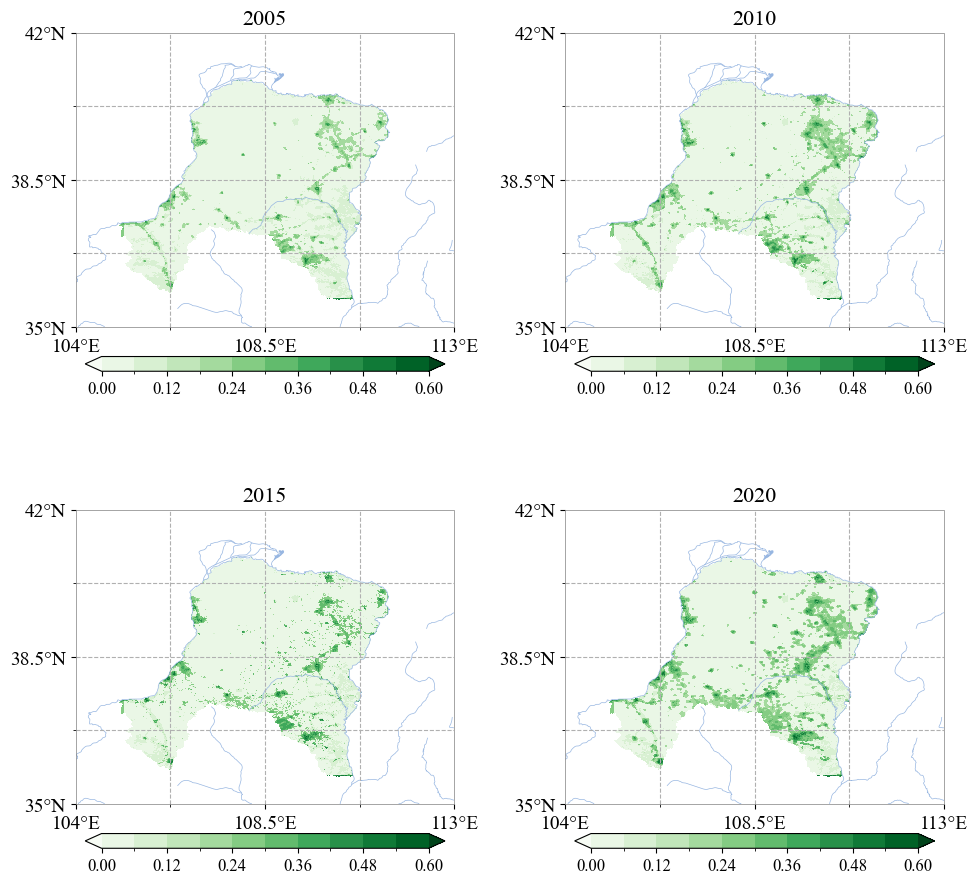

In [37]:
from utils import plot
import matplotlib.pyplot as plt
import cartopy.crs as ccrs
import numpy as np
import matplotlib.font_manager as fm
from matplotlib import rcParams

import xarray as xr

# 读取不同年份的数据
years = [2005, 2010, 2015, 2020]
data_dict = {}
mmaskregion_dict = {}

for year in years:
    file_name = f'data/out_i/out_i_{year}.tif'
    ds = xr.open_dataset(file_name)
    data_dict[year] = ds['band_data'][0]
    mmaskregion_dict[year] = data_dict[year].salem.roi(shape=shpfile)

# 设置Times字体
plt.rcParams['font.family'] = 'Times New Roman'
# 增大字体大小
plt.rcParams['font.size'] = 14

# 创建2x2子图布局
fig = plt.figure(figsize=(10, 10))
proj = ccrs.PlateCarree()
levels = np.linspace(0, 0.6, num=11)

# 创建四个子图
for i, year in enumerate(years):
    ax = fig.add_subplot(2, 2, i+1, projection=proj)
    plot.one_map_region(mmaskregion_dict[year], ax, levels=levels, extents=[104, 113, 35, 42], 
                        cmap="Greens", interval=[4.5, 3.5], mask_ocean=False, 
                        add_coastlines=False, add_land=False, add_gridlines=True, 
                        add_river=True, add_lake=True, add_stock=False, 
                        colorbar=True, plotfunc="pcolormesh", pad=0.1, cbar_fontsize=12)
    ax.set_title(f"{year}", fontsize=16)



# 确保图形完整保存
plt.savefig("fig/multi_year_i.png", dpi=300, bbox_inches='tight')

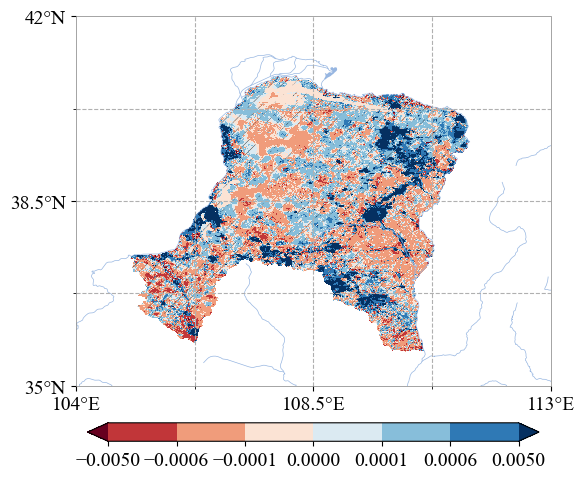

In [31]:
from utils import plot
import matplotlib.pyplot as plt
import cartopy.crs as ccrs
import numpy as np
fig = plt.figure()
proj = ccrs.PlateCarree() #ccrs.Robinson()ccrs.Mollweide()Mollweide()
ax = fig.add_subplot(111, projection=proj)
levels = np.array([-0.005, -0.0006, -0.0001, 0, 0.0001, 0.0006, 0.005])#levels = np.linspace(-1, 1, num=19)
plot.one_map_region(datamaskregion, ax, levels=levels,  cmap="RdBu", extents=[104, 113, 35, 42], interval=[4.5, 3.5], mask_ocean=False, add_coastlines=False, add_land=False, 
                    add_gridlines=True, add_river=True, add_lake=True, add_stock=False, colorbar=True, plotfunc="pcolormesh", pad=0.1, cbar_fontsize=14)
plot.hatch_map(ax, pmaskregion, 3 * "/", label="Lack of model agreement", invert=True, linewidth=0.25, color="#000000")
plt.savefig("fig/trend_i.png", dpi=300, bbox_inches='tight')

## 热点分析

In [11]:
import numpy as np
import rasterio
import os
import matplotlib.pyplot as plt
from scipy import ndimage
from scipy import stats

# 输入和输出文件路径
input_file = "data/out_i/out_i_2020.tif"
output_folder = "data/hotspot"
output_file = os.path.join(output_folder, "hotspot_2020.tif")

# 创建输出文件夹（如果不存在）
os.makedirs(output_folder, exist_ok=True)

# 读取栅格数据
with rasterio.open(input_file) as src:
    # 读取栅格数据值
    raster_data = src.read(1)
    # 保存元数据以便输出
    meta = src.meta.copy()
    # 获取无效值
    nodata = src.nodata
    
    print(f"栅格大小: {raster_data.shape}")
    print(f"NoData值: {nodata}")

# 创建掩码，识别数据有效值
if nodata is not None:
    mask = (raster_data != nodata)
else:
    # 如果没有指定nodata值，假设NaN是无效值
    mask = ~np.isnan(raster_data)

# 计算有效值数量
valid_count = np.sum(mask)
print(f"有效值数量: {valid_count}")

# 获取全局均值和标准差（仅考虑有效值）
global_mean = np.mean(raster_data[mask])
global_std = np.std(raster_data[mask])

print(f"全局均值: {global_mean}")
print(f"全局标准差: {global_std}")

# 定义计算Getis-Ord Gi*的函数
def calculate_getis_ord(array, mask, window_size=5):
    """
    计算Getis-Ord Gi*统计量
    
    参数:
    array: 输入栅格数组
    mask: 有效值掩码
    window_size: 移动窗口大小（奇数，5表示5x5窗口）
    
    返回:
    z_scores: Gi*的Z分数数组
    p_values: 对应的p值数组
    """
    # 创建输出数组
    rows, cols = array.shape
    z_scores = np.full((rows, cols), np.nan)
    p_values = np.full((rows, cols), np.nan)
    
    # 计算窗口半径
    radius = window_size // 2
    
    # 全局统计量
    global_mean = np.mean(array[mask])
    global_std = np.std(array[mask])
    n_total = np.sum(mask)  # 总的有效数据点数
    
    # 定义权重核（等权重）
    weight_kernel = np.ones((window_size, window_size))
    weight_kernel[radius, radius] = 1  # 中心点也计入（Gi*包括中心点）
    
    print(f"使用 {window_size}x{window_size} 窗口进行分析")
    
    # 遍历每个像素
    for i in range(rows):
        if i % 100 == 0:  # 打印进度
            print(f"处理行 {i}/{rows}")
            
        for j in range(cols):
            if not mask[i, j]:
                continue  # 跳过无效值
                
            # 定义窗口边界
            y_min = max(0, i - radius)
            y_max = min(rows, i + radius + 1)
            x_min = max(0, j - radius)
            x_max = min(cols, j + radius + 1)
            
            # 提取窗口
            window = array[y_min:y_max, x_min:x_max]
            window_mask = mask[y_min:y_max, x_min:x_max]
            
            # 仅考虑有效值
            valid_values = window[window_mask]
            
            if len(valid_values) <= 1:
                continue  # 如果没有足够的有效邻居，跳过
                
            # 计算Gi*统计量
            local_sum = np.sum(valid_values)
            n_local = len(valid_values)
            
            # 应用Getis-Ord Gi*公式
            numerator = local_sum - n_local * global_mean
            
            # 计算标准差项
            s = global_std * np.sqrt(((n_total * n_local) - (n_local**2)) / (n_total - 1))
            
            if s > 0:
                gi_star = numerator / s
                z_scores[i, j] = gi_star
                
                # 计算p值（双尾检验）
                p_values[i, j] = 2 * (1 - stats.norm.cdf(abs(gi_star)))
    
    return z_scores, p_values

# 计算Getis-Ord Gi*统计量
print("计算Getis-Ord Gi*统计量...")
z_scores, p_values = calculate_getis_ord(raster_data, mask, window_size=5)  # 使用5x5窗口

# 创建热点结果栅格
print("创建热点结果栅格...")
hotspot_raster = np.full(raster_data.shape, np.nan)

# 标记显著的热点和冷点
# 使用常见的置信水平：90%(1.65), 95%(1.96), 99%(2.58)
hotspot_raster[(z_scores > 1.65) & (z_scores <= 1.96) & (p_values <= 0.1)] = 1  # 90% 热点
hotspot_raster[(z_scores > 1.96) & (z_scores <= 2.58) & (p_values <= 0.05)] = 2  # 95% 热点
hotspot_raster[(z_scores > 2.58) & (p_values <= 0.01)] = 3  # 99% 热点

hotspot_raster[(z_scores < -1.65) & (z_scores >= -1.96) & (p_values <= 0.1)] = -1  # 90% 冷点
hotspot_raster[(z_scores < -1.96) & (z_scores >= -2.58) & (p_values <= 0.05)] = -2  # 95% 冷点
hotspot_raster[(z_scores < -2.58) & (p_values <= 0.01)] = -3  # 99% 冷点

# 不显著的区域设为0（可以选择性地只在有效区域内设置）
hotspot_raster[(p_values > 0.1) & mask] = 0

# 保存热点分析结果
meta.update(
    dtype=rasterio.float32,
    nodata=np.nan
)

with rasterio.open(output_file, 'w', **meta) as dst:
    dst.write(hotspot_raster.astype(rasterio.float32), 1)

print(f"热点分析完成，结果保存至: {output_file}")

# 可视化结果
plt.figure(figsize=(12, 10))

# 创建自定义颜色映射
import matplotlib.colors as colors
cmap = plt.cm.RdBu_r
bounds = [-3, -2, -1, 0, 1, 2, 3]
norm = colors.BoundaryNorm(bounds, cmap.N)

# 绘制热点图
img = plt.imshow(hotspot_raster, cmap=cmap, norm=norm)
colorbar = plt.colorbar(img, ticks=[-2.5, -1.5, -0.5, 0.5, 1.5, 2.5])
colorbar.set_label('Gi* 显著性')
colorbar.ax.set_yticklabels(['99% 冷点', '95% 冷点', '90% 冷点', 
                            '90% 热点', '95% 热点', '99% 热点'])

plt.title('Getis-Ord Gi* 热点分析 (5x5窗口)')
plt.axis('off')

# 保存可视化结果
fig_output = os.path.join(output_folder, "hotspot_2020_visualization.png")
plt.savefig(fig_output, dpi=300, bbox_inches='tight')
plt.close()

print(f"热点可视化结果保存至: {fig_output}")

# 统计各类热点和冷点的数量
unique_values, counts = np.unique(hotspot_raster[~np.isnan(hotspot_raster)], return_counts=True)
stats_dict = dict(zip(unique_values, counts))

print("\n热点/冷点统计:")
if -3 in stats_dict: print(f"99% 冷点: {stats_dict[-3]}")
if -2 in stats_dict: print(f"95% 冷点: {stats_dict[-2]}")
if -1 in stats_dict: print(f"90% 冷点: {stats_dict[-1]}")
if 0 in stats_dict: print(f"不显著: {stats_dict[0]}")
if 1 in stats_dict: print(f"90% 热点: {stats_dict[1]}")
if 2 in stats_dict: print(f"95% 热点: {stats_dict[2]}")
if 3 in stats_dict: print(f"99% 热点: {stats_dict[3]}")

栅格大小: (1164, 1432)
NoData值: None
有效值数量: 1666848
全局均值: 0.10232305012316505
全局标准差: 0.1144371245179678
计算Getis-Ord Gi*统计量...
使用 5x5 窗口进行分析
处理行 0/1164
处理行 100/1164
处理行 200/1164
处理行 300/1164
处理行 400/1164
处理行 500/1164
处理行 600/1164
处理行 700/1164
处理行 800/1164
处理行 900/1164
处理行 1000/1164
处理行 1100/1164
创建热点结果栅格...
热点分析完成，结果保存至: data/hotspot\hotspot_2020.tif


C:\Users\DELL\AppData\Local\Temp\ipykernel_34640\950574752.py:176: UserWarning: Glyph 28909 (\N{CJK UNIFIED IDEOGRAPH-70ED}) missing from current font.
  plt.savefig(fig_output, dpi=300, bbox_inches='tight')
C:\Users\DELL\AppData\Local\Temp\ipykernel_34640\950574752.py:176: UserWarning: Glyph 28857 (\N{CJK UNIFIED IDEOGRAPH-70B9}) missing from current font.
  plt.savefig(fig_output, dpi=300, bbox_inches='tight')
C:\Users\DELL\AppData\Local\Temp\ipykernel_34640\950574752.py:176: UserWarning: Glyph 20998 (\N{CJK UNIFIED IDEOGRAPH-5206}) missing from current font.
  plt.savefig(fig_output, dpi=300, bbox_inches='tight')
C:\Users\DELL\AppData\Local\Temp\ipykernel_34640\950574752.py:176: UserWarning: Glyph 26512 (\N{CJK UNIFIED IDEOGRAPH-6790}) missing from current font.
  plt.savefig(fig_output, dpi=300, bbox_inches='tight')
C:\Users\DELL\AppData\Local\Temp\ipykernel_34640\950574752.py:176: UserWarning: Glyph 31383 (\N{CJK UNIFIED IDEOGRAPH-7A97}) missing from current font.
  plt.savefig(fi

热点可视化结果保存至: data/hotspot\hotspot_2020_visualization.png

热点/冷点统计:
99% 冷点: 734390
95% 冷点: 229267
90% 冷点: 76034
不显著: 179279
90% 热点: 6739
95% 热点: 15343
99% 热点: 424582


In [32]:
import xarray as xr
file_name='data/hotspot/hotspot_2020.tif' 
ds=xr.open_dataset(file_name)
data_hot = ds['band_data'][0]

In [33]:
import salem
import geopandas as gpd
shp_dir='data/shp/catchment.shp'

hot_region=data_hot.salem.roi(shape=shpfile)

d:\miniconda\envs\geo\lib\site-packages\geopandas\geoseries.py:645: FutureWarning: the convert_dtype parameter is deprecated and will be removed in a future version.  Do ``ser.astype(object).apply()`` instead if you want ``convert_dtype=False``.
  result = super().apply(func, convert_dtype=convert_dtype, args=args, **kwargs)


In [ ]:
import xarray as xr
file_name='data/out_i/out_i_2020.tif' 
ds=xr.open_dataset(file_name)
data2020 = ds['band_data'][0]

In [ ]:
file_name='data/trend/mk_pvalue.tif' 
ds=xr.open_dataset(file_name)
p = ds['band_data'][0]
datap = p < 0.05
lat = ds['y']
lon = ds['x']
datap = datap.swap_dims({'y':'lat','x':'lon'})
datap.coords['lat'] = ('lat',lat.to_numpy())
datap.coords['lon'] = ('lon',lon.to_numpy()) # 对维度lon指定新的坐标信息lon
datap = datap.reset_coords(names=['y','x'], drop=True)


In [ ]:
import salem
import geopandas as gpd
shp_dir='data/shp/catchment.shp'
shpfile=gpd.read_file(shp_dir)
pmaskregion=datap.salem.roi(shape=shpfile)
datamaskregion=data.salem.roi(shape=shpfile)
mmaskregion=data2020.salem.roi(shape=shpfile)

d:\miniconda\envs\geo\lib\site-packages\geopandas\geoseries.py:645: FutureWarning: the convert_dtype parameter is deprecated and will be removed in a future version.  Do ``ser.astype(object).apply()`` instead if you want ``convert_dtype=False``.
  result = super().apply(func, convert_dtype=convert_dtype, args=args, **kwargs)
d:\miniconda\envs\geo\lib\site-packages\geopandas\geoseries.py:645: FutureWarning: the convert_dtype parameter is deprecated and will be removed in a future version.  Do ``ser.astype(object).apply()`` instead if you want ``convert_dtype=False``.
  result = super().apply(func, convert_dtype=convert_dtype, args=args, **kwargs)
d:\miniconda\envs\geo\lib\site-packages\geopandas\geoseries.py:645: FutureWarning: the convert_dtype parameter is deprecated and will be removed in a future version.  Do ``ser.astype(object).apply()`` instead if you want ``convert_dtype=False``.
  result = super().apply(func, convert_dtype=convert_dtype, args=args, **kwargs)


d:\miniconda\envs\geo\lib\site-packages\geopandas\geoseries.py:645: FutureWarning: the convert_dtype parameter is deprecated and will be removed in a future version.  Do ``ser.astype(object).apply()`` instead if you want ``convert_dtype=False``.
  result = super().apply(func, convert_dtype=convert_dtype, args=args, **kwargs)
d:\miniconda\envs\geo\lib\site-packages\geopandas\geoseries.py:645: FutureWarning: the convert_dtype parameter is deprecated and will be removed in a future version.  Do ``ser.astype(object).apply()`` instead if you want ``convert_dtype=False``.
  result = super().apply(func, convert_dtype=convert_dtype, args=args, **kwargs)
d:\miniconda\envs\geo\lib\site-packages\geopandas\geoseries.py:645: FutureWarning: the convert_dtype parameter is deprecated and will be removed in a future version.  Do ``ser.astype(object).apply()`` instead if you want ``convert_dtype=False``.
  result = super().apply(func, convert_dtype=convert_dtype, args=args, **kwargs)
d:\miniconda\envs\g

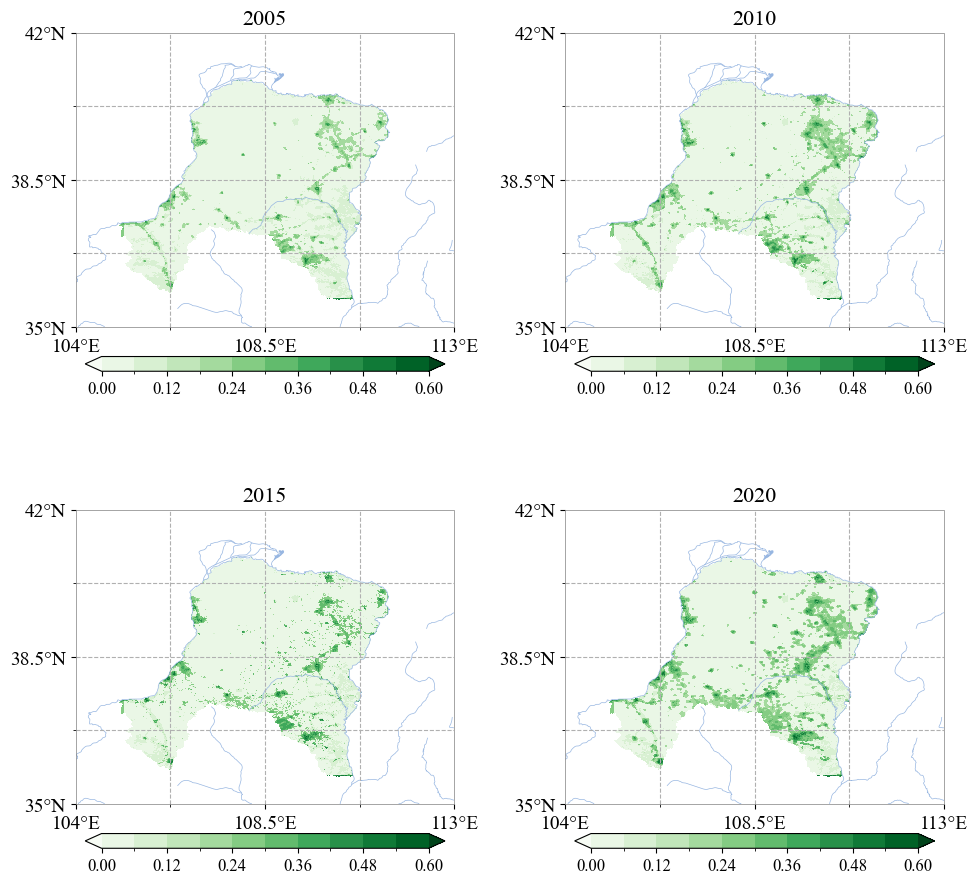

In [ ]:
from utils import plot
import matplotlib.pyplot as plt
import cartopy.crs as ccrs
import numpy as np
import matplotlib.font_manager as fm
from matplotlib import rcParams

import xarray as xr

# 读取不同年份的数据
years = [2005, 2010, 2015, 2020]
data_dict = {}
mmaskregion_dict = {}

for year in years:
    file_name = f'data/out_i/out_i_{year}.tif'
    ds = xr.open_dataset(file_name)
    data_dict[year] = ds['band_data'][0]
    mmaskregion_dict[year] = data_dict[year].salem.roi(shape=shpfile)

# 设置Times字体
plt.rcParams['font.family'] = 'Times New Roman'
# 增大字体大小
plt.rcParams['font.size'] = 14

# 创建2x2子图布局
fig = plt.figure(figsize=(10, 10))
proj = ccrs.PlateCarree()
levels = np.linspace(0, 0.6, num=11)

# 创建四个子图
for i, year in enumerate(years):
    ax = fig.add_subplot(2, 2, i+1, projection=proj)
    plot.one_map_region(mmaskregion_dict[year], ax, levels=levels, extents=[104, 113, 35, 42], 
                        cmap="Greens", interval=[4.5, 3.5], mask_ocean=False, 
                        add_coastlines=False, add_land=False, add_gridlines=True, 
                        add_river=True, add_lake=True, add_stock=False, 
                        colorbar=True, plotfunc="pcolormesh", pad=0.1, cbar_fontsize=12)
    ax.set_title(f"{year}", fontsize=16)



# 确保图形完整保存
plt.savefig("fig/multi_year_i.png", dpi=300, bbox_inches='tight')

In [ ]:
import xarray as xr
file_name='data/out_i/out_i_2020.tif' 
ds=xr.open_dataset(file_name)
data2020 = ds['band_data'][0]

In [ ]:
file_name='data/trend/mk_pvalue.tif' 
ds=xr.open_dataset(file_name)
p = ds['band_data'][0]
datap = p < 0.05
lat = ds['y']
lon = ds['x']
datap = datap.swap_dims({'y':'lat','x':'lon'})
datap.coords['lat'] = ('lat',lat.to_numpy())
datap.coords['lon'] = ('lon',lon.to_numpy()) # 对维度lon指定新的坐标信息lon
datap = datap.reset_coords(names=['y','x'], drop=True)


In [ ]:
import salem
import geopandas as gpd
shp_dir='data/shp/catchment.shp'
shpfile=gpd.read_file(shp_dir)
pmaskregion=datap.salem.roi(shape=shpfile)
datamaskregion=data.salem.roi(shape=shpfile)
mmaskregion=data2020.salem.roi(shape=shpfile)

d:\miniconda\envs\geo\lib\site-packages\geopandas\geoseries.py:645: FutureWarning: the convert_dtype parameter is deprecated and will be removed in a future version.  Do ``ser.astype(object).apply()`` instead if you want ``convert_dtype=False``.
  result = super().apply(func, convert_dtype=convert_dtype, args=args, **kwargs)
d:\miniconda\envs\geo\lib\site-packages\geopandas\geoseries.py:645: FutureWarning: the convert_dtype parameter is deprecated and will be removed in a future version.  Do ``ser.astype(object).apply()`` instead if you want ``convert_dtype=False``.
  result = super().apply(func, convert_dtype=convert_dtype, args=args, **kwargs)
d:\miniconda\envs\geo\lib\site-packages\geopandas\geoseries.py:645: FutureWarning: the convert_dtype parameter is deprecated and will be removed in a future version.  Do ``ser.astype(object).apply()`` instead if you want ``convert_dtype=False``.
  result = super().apply(func, convert_dtype=convert_dtype, args=args, **kwargs)


d:\miniconda\envs\geo\lib\site-packages\geopandas\geoseries.py:645: FutureWarning: the convert_dtype parameter is deprecated and will be removed in a future version.  Do ``ser.astype(object).apply()`` instead if you want ``convert_dtype=False``.
  result = super().apply(func, convert_dtype=convert_dtype, args=args, **kwargs)
d:\miniconda\envs\geo\lib\site-packages\geopandas\geoseries.py:645: FutureWarning: the convert_dtype parameter is deprecated and will be removed in a future version.  Do ``ser.astype(object).apply()`` instead if you want ``convert_dtype=False``.
  result = super().apply(func, convert_dtype=convert_dtype, args=args, **kwargs)
d:\miniconda\envs\geo\lib\site-packages\geopandas\geoseries.py:645: FutureWarning: the convert_dtype parameter is deprecated and will be removed in a future version.  Do ``ser.astype(object).apply()`` instead if you want ``convert_dtype=False``.
  result = super().apply(func, convert_dtype=convert_dtype, args=args, **kwargs)
d:\miniconda\envs\g

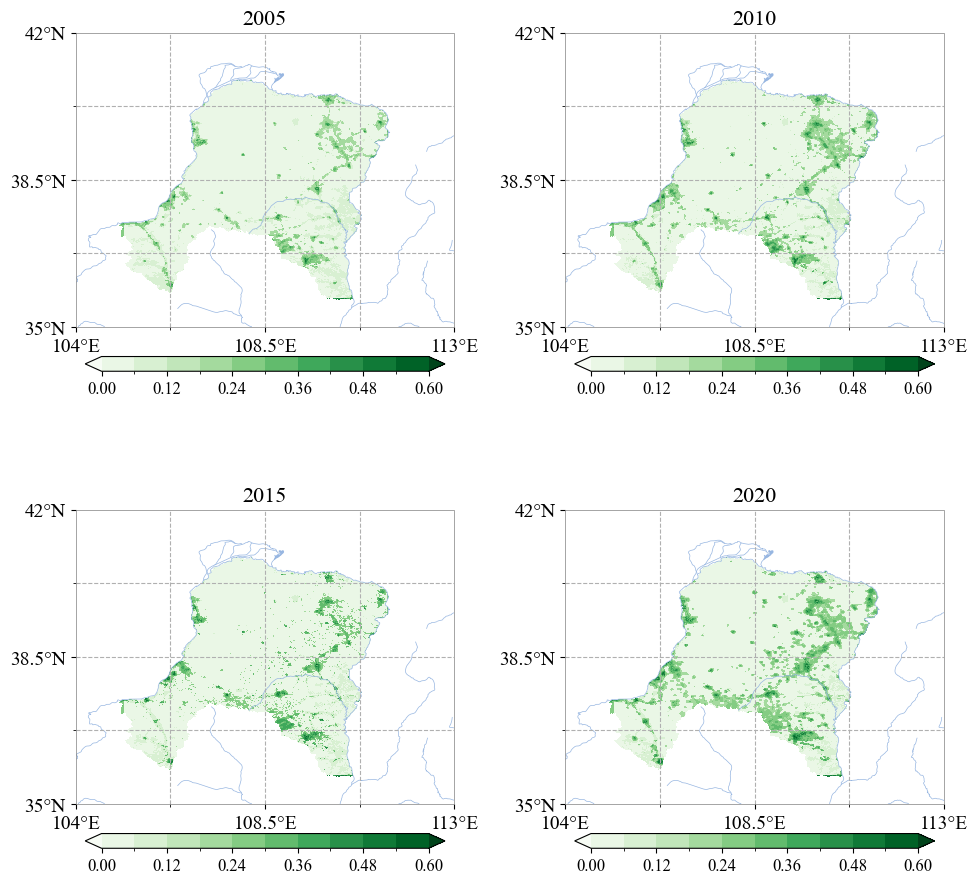

In [ ]:
from utils import plot
import matplotlib.pyplot as plt
import cartopy.crs as ccrs
import numpy as np
import matplotlib.font_manager as fm
from matplotlib import rcParams

import xarray as xr

# 读取不同年份的数据
years = [2005, 2010, 2015, 2020]
data_dict = {}
mmaskregion_dict = {}

for year in years:
    file_name = f'data/out_i/out_i_{year}.tif'
    ds = xr.open_dataset(file_name)
    data_dict[year] = ds['band_data'][0]
    mmaskregion_dict[year] = data_dict[year].salem.roi(shape=shpfile)

# 设置Times字体
plt.rcParams['font.family'] = 'Times New Roman'
# 增大字体大小
plt.rcParams['font.size'] = 14

# 创建2x2子图布局
fig = plt.figure(figsize=(10, 10))
proj = ccrs.PlateCarree()
levels = np.linspace(0, 0.6, num=11)

# 创建四个子图
for i, year in enumerate(years):
    ax = fig.add_subplot(2, 2, i+1, projection=proj)
    plot.one_map_region(mmaskregion_dict[year], ax, levels=levels, extents=[104, 113, 35, 42], 
                        cmap="Greens", interval=[4.5, 3.5], mask_ocean=False, 
                        add_coastlines=False, add_land=False, add_gridlines=True, 
                        add_river=True, add_lake=True, add_stock=False, 
                        colorbar=True, plotfunc="pcolormesh", pad=0.1, cbar_fontsize=12)
    ax.set_title(f"{year}", fontsize=16)



# 确保图形完整保存
plt.savefig("fig/multi_year_i.png", dpi=300, bbox_inches='tight')

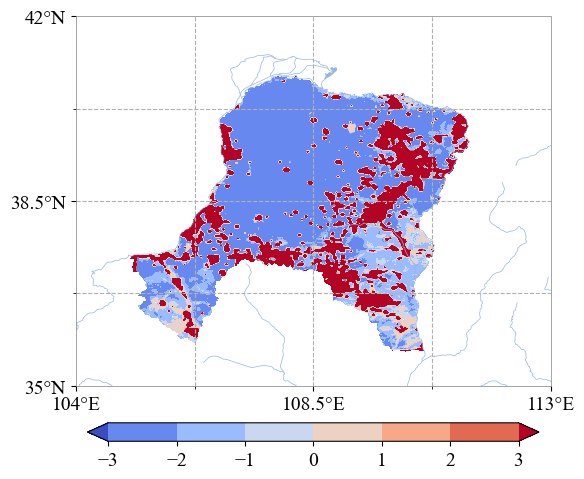

In [34]:
from utils import plot
import matplotlib.pyplot as plt
import cartopy.crs as ccrs
import numpy as np
import matplotlib.font_manager as fm
from matplotlib import rcParams

# 设置Times字体
plt.rcParams['font.family'] = 'Times New Roman'
# 增大字体大小
plt.rcParams['font.size'] = 14



fig = plt.figure()
proj = ccrs.PlateCarree() #ccrs.Robinson()ccrs.Mollweide()Mollweide()
ax = fig.add_subplot(111, projection=proj)
levels =  np.linspace(-3, 3, num=7)
plot.one_map_region(hot_region, ax, levels=levels,  extents=[104, 113, 35, 42], cmap="coolwarm", interval=[4.5, 3.5], mask_ocean=False, add_coastlines=False, add_land=False, 
                    add_gridlines=True, add_river=True, add_lake=True, add_stock=False, colorbar=True, plotfunc="pcolormesh", pad=0.1, cbar_fontsize=14)
plt.savefig("fig/hots.png", dpi=300, bbox_inches='tight')

## 土地覆盖转移

In [5]:
import numpy as np
import rasterio
import os
import matplotlib.pyplot as plt
import pandas as pd
import salem
import geopandas as gpd
from matplotlib.colors import ListedColormap
import matplotlib.patheffects as pe
from matplotlib.sankey import Sankey
import seaborn as sns
import rioxarray as rxr

# 增大字体大小
plt.rcParams['font.sans-serif'] = ['Microsoft YaHei', 'SimHei', 'Arial Unicode MS']  # Priority fonts
plt.rcParams['axes.unicode_minus'] = False  # Fix negative sign display issue
plt.rcParams.update({'font.size': 20}) # 设置字体大小


# 输入文件路径
lc_2001_file = "data/lc/MCD12_2001.tif"  # 2001年土地覆盖
lc_2021_file = "data/lc/MCD12_2021.tif"  # 2021年土地覆盖
shp_file = "data/shp/catchment.shp"  # 流域边界shapefile

# 创建输出文件夹
output_folder = "data/landcover_change"
os.makedirs(output_folder, exist_ok=True)

print("加载流域边界数据...")
# 读取流域边界shapefile
shpfile = gpd.read_file(shp_file)
print(f"流域数据CRS: {shpfile.crs}")

# MODIS土地覆盖类型定义（IGBP分类）
lc_classes = {
    0: "水体",
    1: "常绿针叶林",
    2: "常绿阔叶林",
    3: "落叶针叶林",
    4: "落叶阔叶林",
    5: "混交林",
    6: "封闭灌丛",
    7: "开放灌丛",
    8: "木本稀树草原",
    9: "稀树草原",
    10: "草地",
    11: "永久湿地",
    12: "农田",
    13: "城市和建筑用地",
    14: "农田/自然植被镶嵌体",
    15: "雪和冰",
    16: "裸地",
    17: "未分类"
}

# 为了桑基图，我们简化土地覆盖类型
simplified_classes = {
    0: "水体",
    1: "森林",
    2: "森林",
    3: "森林",
    4: "森林",
    5: "森林",
    6: "灌丛",
    7: "灌丛",
    8: "草地",
    9: "草地",
    10: "草地",
    11: "湿地",
    12: "农田",
    13: "城市",
    14: "农田",
    15: "冰雪",
    16: "裸地",
    17: "其他"
}

# 简化后的类别
simple_class_colors = {
    "水体": "#3366FF",
    "森林": "#006400",  
    "灌丛": "#90EE90",
    "草地": "#FFFF00",
    "湿地": "#00FFFF",
    "农田": "#FFD700",
    "城市": "#FF0000",
    "冰雪": "#FFFFFF",
    "裸地": "#D2B48C",
    "其他": "#808080"
}

# 为每个土地覆盖类别定义颜色
igbp_colors = {
    0: "#3366FF",  # 水体 - 蓝色
    1: "#006400",  # 常绿针叶林 - 深绿色
    2: "#228B22",  # 常绿阔叶林 - 森林绿
    3: "#556B2F",  # 落叶针叶林 - 橄榄绿
    4: "#8FBC8F",  # 落叶阔叶林 - 暗海绿
    5: "#2E8B57",  # 混交林 - 海绿色
    6: "#90EE90",  # 封闭灌丛 - 淡绿色
    7: "#98FB98",  # 开放灌丛 - 浅绿色
    8: "#ADFF2F",  # 木本稀树草原 - 绿黄色
    9: "#7FFF00",  # 稀树草原 - 黄绿色
    10: "#FFFF00", # 草地 - 黄色
    11: "#00FFFF", # 永久湿地 - 青色
    12: "#FFD700", # 农田 - 金色
    13: "#FF0000", # 城市和建筑用地 - 红色
    14: "#DAA520", # 农田/自然植被镶嵌体 - 金菊黄
    15: "#FFFFFF", # 雪和冰 - 白色
    16: "#D2B48C", # 裸地 - 棕褐色
    17: "#808080"  # 未分类 - 灰色
}

print("读取土地覆盖数据...")
# 使用salem读取栅格数据并用流域边界裁剪
def load_and_clip_raster(raster_file, shpfile):
    """读取栅格数据并用流域边界裁剪"""
    # 读取栅格数据
    
    ds = rxr.open_rasterio(raster_file)

    # 将栅格裁剪到流域边界
    clipped_ds = ds.salem.roi(shape=shpfile)
    # 转换为numpy数组
    clipped_data = clipped_ds.values
    
    return clipped_data

# 读取并裁剪2001年和2021年的土地覆盖数据
try:
    lc_2001 = load_and_clip_raster(lc_2001_file, shpfile)
    lc_2021 = load_and_clip_raster(lc_2021_file, shpfile)
    
    print(f"2001年土地覆盖数据形状: {lc_2001.shape}")
    print(f"2021年土地覆盖数据形状: {lc_2021.shape}")
    
    # 检查数据有效性
    if lc_2001.size == 0 or lc_2021.size == 0:
        raise ValueError("裁剪后的栅格数据为空，请检查流域边界是否与栅格数据重叠")
    
    # 获取有效像素数量
    valid_pixels_2001 = (~np.isnan(lc_2001)).sum()
    valid_pixels_2021 = (~np.isnan(lc_2021)).sum()
    
    print(f"2001年有效像素数量: {valid_pixels_2001}")
    print(f"2021年有效像素数量: {valid_pixels_2021}")
    
    
except Exception as e:
    print(f"读取或裁剪数据时出错: {e}")
    raise

print("生成土地覆盖变化统计...")
# 创建转移矩阵（用于分析土地覆盖变化）
def create_transition_matrix(lc_before, lc_after, classes):
    """创建土地覆盖转移矩阵"""
    # 确保数据形状一致
    if lc_before.shape != lc_after.shape:
        raise ValueError("输入栅格形状不一致")
    
    # 获取有效的类别
    classes_before = sorted(np.unique(lc_before[~np.isnan(lc_before)]).astype(int))
    classes_after = sorted(np.unique(lc_after[~np.isnan(lc_after)]).astype(int))
    unique_classes = sorted(set(classes_before).union(set(classes_after)))
    
    # 仅保留类别字典中定义的类别
    valid_classes = [c for c in unique_classes if c in classes]
    
    # 初始化转移矩阵
    n_classes = len(valid_classes)
    transition_matrix = np.zeros((n_classes, n_classes))
    
    # 创建有效数据掩码
    mask = ~np.isnan(lc_before) & ~np.isnan(lc_after)
    lc_before_flat = lc_before[mask].astype(int)
    lc_after_flat = lc_after[mask].astype(int)
    
    # 填充转移矩阵
    for i, class_before in enumerate(valid_classes):
        for j, class_after in enumerate(valid_classes):
            # 计算从class_before变为class_after的像素数量
            transition_matrix[i, j] = np.sum(
                (lc_before_flat == class_before) & (lc_after_flat == class_after)
            )
    
    # 创建DataFrame便于分析
    df_matrix = pd.DataFrame(
        transition_matrix,
        index=[classes[c] for c in valid_classes],
        columns=[classes[c] for c in valid_classes]
    )
    
    return df_matrix, valid_classes

# 创建IGBP分类的转移矩阵
transition_matrix, valid_classes = create_transition_matrix(lc_2001, lc_2021, lc_classes)

# 保存转移矩阵到CSV
matrix_file = os.path.join(output_folder, "transition_matrix_2001_2021.csv")
transition_matrix.to_csv(matrix_file, encoding='utf-8-sig')
print(f"转移矩阵已保存至: {matrix_file}")

print("绘制土地覆盖变化可视化...")
# 绘制转移矩阵热图
plt.figure(figsize=(14, 12))
# 使用对数缩放更好地显示数据范围
matrix_log = np.log1p(transition_matrix)  # log(1+x)避免log(0)
mask = (transition_matrix == 0)  # 掩盖为0的单元格

# 绘制热图
ax = sns.heatmap(matrix_log, annot=transition_matrix, fmt=".0f", 
                cmap="YlGnBu", mask=mask, cbar_kws={'label': '像素数量 (对数缩放)'})

plt.title("2001-2021年土地覆盖转移矩阵", fontsize=16)
plt.xlabel("2021年土地覆盖类型", fontsize=14)
plt.ylabel("2001年土地覆盖类型", fontsize=14)

# 调整标签方向以提高可读性
plt.xticks(rotation=45, ha='right')
plt.yticks(rotation=0)

# 保存转移矩阵图
matrix_plot_file = os.path.join(output_folder, "transition_matrix_plot.png")
plt.tight_layout()
plt.savefig(matrix_plot_file, dpi=300)
plt.close()
print(f"转移矩阵图已保存至: {matrix_plot_file}")



# 绘制土地覆盖类别分布比较图
def plot_landcover_distribution(lc_2001, lc_2021, classes, colors, output_file):
    """绘制土地覆盖类别分布比较图"""
    # 统计各类别像素数量
    classes_2001 = {}
    classes_2021 = {}
    
    # 获取有效数据
    mask_2001 = ~np.isnan(lc_2001)
    mask_2021 = ~np.isnan(lc_2021)
    
    lc_2001_valid = lc_2001[mask_2001].astype(int)
    lc_2021_valid = lc_2021[mask_2021].astype(int)
    
    # 计算各类别像素数量
    for c in classes:
        classes_2001[c] = np.sum(lc_2001_valid == c)
        classes_2021[c] = np.sum(lc_2021_valid == c)
    
    # 过滤掉不存在的类别
    existing_classes = [c for c in classes if classes_2001[c] > 0 or classes_2021[c] > 0]
    
    # 准备绘图数据
    class_names = [classes[c] for c in existing_classes]
    count_2001 = [classes_2001[c] for c in existing_classes]
    count_2021 = [classes_2021[c] for c in existing_classes]
    
    # 转换为百分比
    total_2001 = sum(count_2001)
    total_2021 = sum(count_2021)
    
    percent_2001 = [count / total_2001 * 100 for count in count_2001]
    percent_2021 = [count / total_2021 * 100 for count in count_2021]
    
    # 绘制条形图
    fig, ax = plt.subplots(figsize=(12, 8))
    
    x = np.arange(len(class_names))
    width = 0.35
    
    bar_colors = [colors[c] for c in existing_classes]
    
    rects1 = ax.bar(x - width/2, percent_2001, width, label='2001年', color=bar_colors, alpha=0.7)
    rects2 = ax.bar(x + width/2, percent_2021, width, label='2021年', color=bar_colors, alpha=1.0)
    
    # 添加标签和标题
    ax.set_ylabel('占比 (%)', fontsize=14)
    ax.set_title('2001年与2021年土地覆盖分布比较', fontsize=16)
    ax.set_xticks(x)
    ax.set_xticklabels(class_names, rotation=45, ha='right')
    ax.legend()
    
    # 为每个柱子添加数值标签
    def autolabel(rects, percentages):
        for i, rect in enumerate(rects):
            height = percentages[i]
            if height > 1.0:  # 只标注大于1%的值
                ax.annotate(f'{height:.1f}%',
                            xy=(rect.get_x() + rect.get_width() / 2, height),
                            xytext=(0, 3),  # 3点垂直偏移
                            textcoords="offset points",
                            ha='center', va='bottom',
                            fontsize=10,
                            path_effects=[pe.withStroke(linewidth=3, foreground='white')])
    
    autolabel(rects1, percent_2001)
    autolabel(rects2, percent_2021)
    
    plt.tight_layout()
    plt.savefig(output_file, dpi=300)
    plt.close()
    
    print(f"土地覆盖分布图已保存至: {output_file}")

# 绘制IGBP分类的土地覆盖分布图
distribution_plot_file = os.path.join(output_folder, "landcover_distribution_2001_2021.png")
plot_landcover_distribution(lc_2001, lc_2021, lc_classes, igbp_colors, distribution_plot_file)

# 绘制简化分类的土地覆盖分布图
simple_distribution_plot_file = os.path.join(output_folder, "simplified_landcover_distribution_2001_2021.png")

# 首先需要将栅格值映射到简化类别
def map_to_simplified(lc_raster, simplified_classes):
    """将土地覆盖栅格映射到简化类别"""
    result = np.zeros_like(lc_raster)
    # 创建映射字典，用于将原始类别ID映射到简化类别的唯一ID
    simple_class_to_id = {class_name: i for i, class_name in enumerate(set(simplified_classes.values()))}
    id_to_simple_class = {i: class_name for class_name, i in simple_class_to_id.items()}
    
    # 应用映射
    for orig_id, simple_class in simplified_classes.items():
        simple_id = simple_class_to_id[simple_class]
        mask = (lc_raster == orig_id)
        result[mask] = simple_id
    
    # 复制NaN值
    result[np.isnan(lc_raster)] = np.nan
    
    return result, id_to_simple_class

# 映射到简化类别
lc_2001_simple, id_to_simple_2001 = map_to_simplified(lc_2001, simplified_classes)
lc_2021_simple, id_to_simple_2021 = map_to_simplified(lc_2021, simplified_classes)

# 创建简化类别的颜色映射
simple_id_colors = {i: simple_class_colors[class_name] for i, class_name in id_to_simple_2001.items()}

# 绘制简化类别的分布图
plot_landcover_distribution(lc_2001_simple, lc_2021_simple, id_to_simple_2001, simple_id_colors, simple_distribution_plot_file)




print("计算土地覆盖变化统计...")
# 计算变化最显著的土地覆盖转换
def analyze_major_changes(transition_df, threshold=0.05):
    """分析主要的土地覆盖变化"""
    # 计算每种类型2001年的总面积
    totals_2001 = transition_df.sum(axis=1)
    
    # 计算每种类型2021年的总面积
    totals_2021 = transition_df.sum(axis=0)
    
    # 计算各类型的净变化（面积和百分比）
    net_change = totals_2021 - totals_2001
    percent_change = (net_change / totals_2001 * 100).replace([np.inf, -np.inf], np.nan).fillna(0)
    
    # 创建变化分析结果DataFrame
    change_analysis = pd.DataFrame({
        '2001年面积': totals_2001,
        '2021年面积': totals_2021,
        '净变化': net_change,
        '变化率(%)': percent_change
    })
    
    # 计算主要转换路径
    major_transitions = []
    
    for source in transition_df.index:
        for target in transition_df.columns:
            if source != target:  # 排除未变化的单元格
                value = transition_df.loc[source, target]
                source_total = totals_2001[source]
                
                # 计算从source转变为target的比例
                if source_total > 0:
                    percentage = value / source_total * 100
                    
                    # 只考虑显著变化
                    if percentage > threshold * 100:
                        major_transitions.append({
                            '原始类型': source,
                            '目标类型': target,
                            '转换像素数': value,
                            '占原始类型百分比': percentage
                        })
    
    # 转换为DataFrame并按百分比排序
    major_transitions_df = pd.DataFrame(major_transitions)
    if not major_transitions_df.empty:
        major_transitions_df = major_transitions_df.sort_values('占原始类型百分比', ascending=False)
    
    return change_analysis, major_transitions_df



# 保存变化分析结果
change_analysis_file = os.path.join(output_folder, "landcover_change_analysis.csv")


major_transitions_file = os.path.join(output_folder, "major_landcover_transitions.csv")


print(f"变化分析结果已保存至: {change_analysis_file}")
print(f"主要土地覆盖转换已保存至: {major_transitions_file}")





加载流域边界数据...
流域数据CRS: epsg:4326
读取土地覆盖数据...


d:\miniconda\envs\geo\lib\site-packages\geopandas\geoseries.py:645: FutureWarning: the convert_dtype parameter is deprecated and will be removed in a future version.  Do ``ser.astype(object).apply()`` instead if you want ``convert_dtype=False``.
  result = super().apply(func, convert_dtype=convert_dtype, args=args, **kwargs)
d:\miniconda\envs\geo\lib\site-packages\geopandas\geoseries.py:645: FutureWarning: the convert_dtype parameter is deprecated and will be removed in a future version.  Do ``ser.astype(object).apply()`` instead if you want ``convert_dtype=False``.
  result = super().apply(func, convert_dtype=convert_dtype, args=args, **kwargs)


2001年土地覆盖数据形状: (1, 1164, 1432)
2021年土地覆盖数据形状: (1, 1164, 1432)
2001年有效像素数量: 914603
2021年有效像素数量: 914603
生成土地覆盖变化统计...
转移矩阵已保存至: data/landcover_change\transition_matrix_2001_2021.csv
绘制土地覆盖变化可视化...
转移矩阵图已保存至: data/landcover_change\transition_matrix_plot.png
土地覆盖分布图已保存至: data/landcover_change\landcover_distribution_2001_2021.png
土地覆盖分布图已保存至: data/landcover_change\simplified_landcover_distribution_2001_2021.png
计算土地覆盖变化统计...
变化分析结果已保存至: data/landcover_change\landcover_change_analysis.csv
主要土地覆盖转换已保存至: data/landcover_change\major_landcover_transitions.csv


## 突变点检测

d:\miniconda\envs\geo\lib\site-packages\geopandas\geoseries.py:645: FutureWarning: the convert_dtype parameter is deprecated and will be removed in a future version.  Do ``ser.astype(object).apply()`` instead if you want ``convert_dtype=False``.
  result = super().apply(func, convert_dtype=convert_dtype, args=args, **kwargs)


Year 2001: Mean = 0.0542, Std = 0.0544


d:\miniconda\envs\geo\lib\site-packages\geopandas\geoseries.py:645: FutureWarning: the convert_dtype parameter is deprecated and will be removed in a future version.  Do ``ser.astype(object).apply()`` instead if you want ``convert_dtype=False``.
  result = super().apply(func, convert_dtype=convert_dtype, args=args, **kwargs)


Year 2002: Mean = 0.0540, Std = 0.0570


d:\miniconda\envs\geo\lib\site-packages\geopandas\geoseries.py:645: FutureWarning: the convert_dtype parameter is deprecated and will be removed in a future version.  Do ``ser.astype(object).apply()`` instead if you want ``convert_dtype=False``.
  result = super().apply(func, convert_dtype=convert_dtype, args=args, **kwargs)


...

Year 2018: Mean = 0.0799, Std = 0.0999


d:\miniconda\envs\geo\lib\site-packages\geopandas\geoseries.py:645: FutureWarning: the convert_dtype parameter is deprecated and will be removed in a future version.  Do ``ser.astype(object).apply()`` instead if you want ``convert_dtype=False``.
  result = super().apply(func, convert_dtype=convert_dtype, args=args, **kwargs)


Year 2019: Mean = 0.0865, Std = 0.1056


d:\miniconda\envs\geo\lib\site-packages\geopandas\geoseries.py:645: FutureWarning: the convert_dtype parameter is deprecated and will be removed in a future version.  Do ``ser.astype(object).apply()`` instead if you want ``convert_dtype=False``.
  result = super().apply(func, convert_dtype=convert_dtype, args=args, **kwargs)


Year 2020: Mean = 0.0894, Std = 0.1033
结果已保存至 data/out_i/annual_statistics.csv


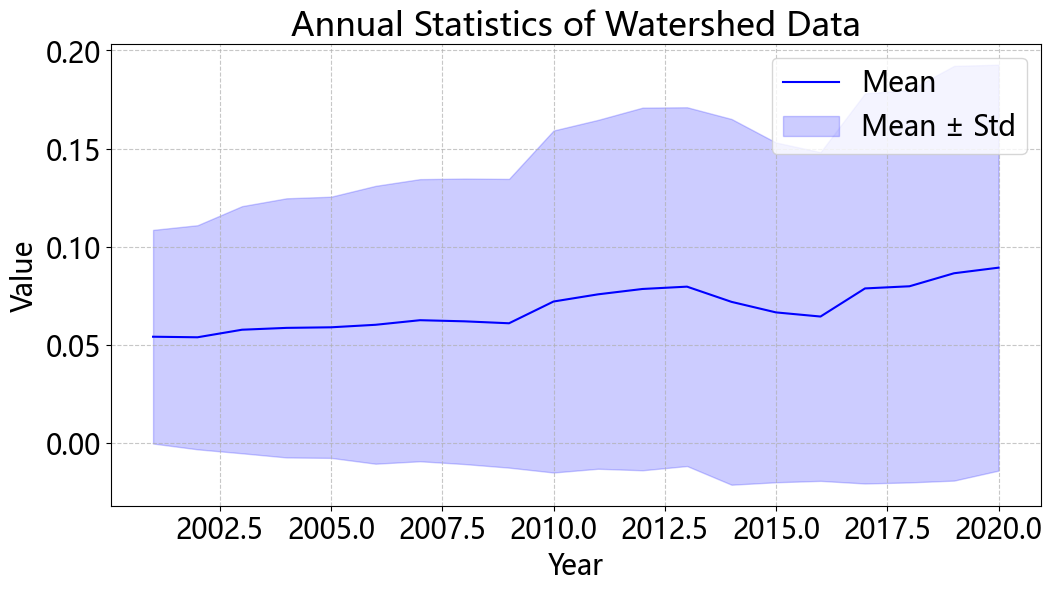

处理完成！


In [11]:
import xarray as xr
import rioxarray as rxr
import numpy as np
import matplotlib.pyplot as plt
import glob
import pandas as pd
import os

# 获取所有年份的tif文件
tif_files = sorted(glob.glob('data/out_i/out_i_*.tif'))
years = [int(f.split('_')[-1].split('.')[0]) for f in tif_files]

# 读取流域shapefile
shpfile = "data/shp/catchment.shp"  # 请替换为你的流域shapefile路径

# 初始化存储结果的列表
annual_means = []
annual_stds = []

# 处理每个年份的数据
for tif_file in tif_files:
    # 读取栅格数据
    ds = rxr.open_rasterio(tif_file)  # 注意：使用open_rasterio而不是open_dataset
    data = ds[0]  # 获取第一个波段
    
    # 使用salem进行流域掩膜
    try:
        import salem
        # 修复 FutureWarning，避免使用默认的 convert_dtype 参数
        # 使用 astype(object).apply() 替代直接调用 apply()
        if hasattr(data, 'salem'):
            masked_data = data.salem.roi(shape=shpfile)
        else:
            # 如果 data 是 GeoSeries 对象，使用推荐的方法
            import geopandas as gpd
            gdf = gpd.read_file(shpfile)
            # 确保使用正确的方法避免警告
            if isinstance(data, gpd.GeoSeries):
                masked_data = data.astype(object).apply(lambda x: x if x.within(gdf.geometry.iloc[0]) else np.nan)
            else:
                masked_data = data.salem.roi(shape=shpfile)
        
        # 计算掩膜区域的平均值和标准差
        valid_data = masked_data.values[~np.isnan(masked_data.values)]
        mean_val = np.mean(valid_data)
        std_val = np.std(valid_data)
        
        # 记录结果
        year = int(tif_file.split('_')[-1].split('.')[0])
        annual_means.append(mean_val)
        annual_stds.append(std_val)
        
        print(f"Year {year}: Mean = {mean_val:.4f}, Std = {std_val:.4f}")
    
    except Exception as e:
        print(f"Error processing {tif_file}: {e}")

# 创建结果DataFrame
results_df = pd.DataFrame({
    'Year': years,
    'Mean': annual_means,
    'Std': annual_stds,
    'Mean+Std': np.array(annual_means) + np.array(annual_stds),
    'Mean-Std': np.array(annual_means) - np.array(annual_stds)
})

# 保存为CSV
output_csv = 'data/out_i/annual_statistics.csv'
results_df.to_csv(output_csv, index=False)
print(f"结果已保存至 {output_csv}")

# 绘制时间序列图
plt.figure(figsize=(12, 6))
plt.plot(years, annual_means, 'b-', label='Mean')
plt.fill_between(years, 
                 np.array(annual_means) - np.array(annual_stds),
                 np.array(annual_means) + np.array(annual_stds),
                 color='b', alpha=0.2, label='Mean ± Std')

plt.xlabel('Year')
plt.ylabel('Value')
plt.title('Annual Statistics of Watershed Data')
plt.grid(True, linestyle='--', alpha=0.7)
plt.legend()

# 保存图表
#plt.savefig('data/out_i/annual_statistics_plot.png', dpi=300, bbox_inches='tight')
plt.show()

print("处理完成！")